# When does a swarm of LLM agents pay off? A local, GPU-only study of cost and quality

**Julián Andrés Mendoza Castro · Esteban Gaviria Zambrano** · Artificial Intelligence G1, Universidad Icesi · V4.2 · October 12, 2026

**Research question.** Does adding agents and communication improve quality enough to justify the extra computation, and under which conditions?

**Why this design (V4.0).** A first experiment with a strong API model (DeepSeek-V4.1-Flash, V3.x of this notebook) solved 100% of the tasks with a single agent. With no room to improve, it could only show that coordination costs more. This study therefore uses **small local models**, for which a single agent still makes mistakes, so the benefit of a swarm can be measured in both directions.

| Factor | Design |
|---|---|
| Models | Two capability pairs, each run **100% on the same GPU**: Qwen 2.5 (3B strong / 1.5B weak) and Llama 3.2 (3B strong / 1B weak) |
| Teams | **weak swarm** (queen and workers weak) and **mixed swarm** (strong queen, weak workers) |
| Architectures | single agent; hierarchical (queen → workers → queen); mesh (hierarchical + one all-to-all review round) |
| Workers *n* | 2, 4 |
| Baselines | strong single agent, weak single agent, and **equal-compute voting**: majority of *k* weak single-agent samples |
| Domains | GSM8K-Platinum and MATH-500 (exact match), Cartagena trip plan (7-criterion rubric; rated by an LLM, see amendment C) |
| Cost metrics | **GPU-seconds** (prompt processing + generation, from Ollama), **GPU energy** (integrated GPU power, 20 Hz), tokens, calls, messages, wall time |
| Controls | identical prompts, temperature, output limit and context window (`num_ctx` 8,192); one call at a time; every model verified 100% on GPU; laptop on AC power in performance mode for the whole experiment |

> **No result in this notebook is invented.** With `BACKEND = "mock"` the pipeline runs on fake answers and every output is stamped **MOCK DATA**. Experimental numbers only come from `BACKEND = "ollama"` runs.

## Pre-registered hypotheses and analysis plan (written on 2026-10-11, before any V4.0 run)

| # | Hypothesis | Test |
|---|---|---|
| H1 | **Cost is structural.** GPU-seconds, energy and tokens grow with the number of calls and messages (hierarchical *n*+2 calls, mesh 2*n*+2), and mesh grows faster because each reviewer reads all *n* drafts. | Measured vs. formula; growth ratios vs. the weak single agent. |
| H2 | **A weak swarm changes the accuracy of the weak single agent.** Two-sided: it can help (division of work, review) or hurt (coordination errors). | Per-problem paired difference: bootstrap 95% CI and sign-flip permutation test. |
| H3 | **Collaboration vs. more samples.** A swarm beats majority voting over weak single-agent samples with a comparable number of calls (hier-2 vs. vote@3; hier-4 and mesh-2 vs. vote@5; mesh-4 vs. vote@9). | Same paired test. |
| H4 | **A strong queen with weak workers vs. the strong model alone.** Accuracy and GPU-seconds of mixed swarms against the strong single agent. | Same paired test, plus the cost ratio. |
| H5 | **The queen matters.** Mixed swarms have fewer plan failures and lose fewer correct worker answers than weak swarms of the same shape. | Paired accuracy test; rates of `plan_invalid_json`, `plan_role_mismatch` and `queen_outcome = lost`. |
| H6 | **Coordination behaviour.** How often the queen keeps, loses or rescues a correct answer, and whether the mesh review improves or worsens the workers. | Descriptive rates with CIs. |
| H7 | **Errors are correlated.** Majority voting over samples of one model stays below Condorcet's prediction under independence. | Measured vote@k vs. the binomial prediction; mean pairwise error correlation φ. |
| H8 | **Agnosticism.** Both families rank the configurations similarly. Exploratory, with two families. | Kendall's τ between families. |

**Multiple comparisons.** H2–H5 contrasts are reported with raw p-values and Holm-adjusted p-values over all pre-registered contrasts.

**Difficulty calibration (decision rule, fixed in advance).** Calibration uses separate problems that are never evaluated. A verifiable domain is informative for a family when the weak single agent solves between 10% and 90% of the calibration problems. If MATH level 5 falls below 10% for the weak model of both families, the level is lowered to 3, then to 2, and calibrated again. Every calibration result is reported, whatever the decision.

**Reporting.** All configurations and all outcomes are reported, favourable or not to swarms.

**Calibration outcome (2026-10-11).** Weak single-agent accuracy on the calibration problems: GSM8K 55% (Qwen) and 55% (Llama), MATH level 5 15% (Qwen) and 0% (Llama). Following the rule, MATH stays at level 5 (only one family is at the floor); Llama on MATH is reported as a floor regime.

**Protocol amendment B (2026-10-11, decided before any evaluation result was analysed).** To fit the experiment in one night of computation (~9 h instead of ~14 h), MATH is evaluated on the first 20 of its 30 sampled problems, with one repetition per swarm configuration. GSM8K keeps 50 problems and two repetitions. The calibration set is unchanged. The reason is computation time only.

**Protocol amendment C (2026-10-12, after the grid, before any Cartagena score was seen).** The plan called for two human raters. The authors delegated the rating of the 40 blind Cartagena answers to an **LLM rater (Claude Opus 5.5)**. It rated blind from `cartagena_answers_blind.md` and `RUBRIC.md`, wrote its operational reading of each criterion in `RATER_NOTES_claude.md`, and opened the key only after scoring every item. Cartagena quality is therefore an **LLM rubric score, not a human evaluation**, and there is a single rater, so no inter-rater agreement. The folder keeps its original name `human_eval/`. Many swarm answers hit the 1,024-token output limit (`final_truncated`). The authors decided not to re-run them with a larger limit, so truncation is reported as a cost of the swarm.

**V4.2 versus V4.1.** Identical analysis; V4.2 also writes the analysis tables to `results_local/tables/` (read by the paper's figure script).

**V4.1 versus V4.0.** Same code, prompts and data. V4.1 adds the `ANALYSIS_ONLY` switch, the LLM-rater labels, a Cartagena rubric table, readable log axes in Figure 1, and the conclusions (section 13).

## How to run

1. **Experiment server.** Start the dedicated Ollama server with `scripts/ollama_experiment_server.sh`. It listens on `127.0.0.1:11435` with flash attention and an 8-bit KV cache, so that all four models fit fully in 4 GB of VRAM with an 8,192-token context. Without these settings, `llama3.2:3b` ran only 90% on GPU.
2. **Models.** Run `ollama pull` for `qwen2.5:3b`, `qwen2.5:1.5b`, `llama3.2:3b` and `llama3.2:1b`.
3. **Pipeline test (optional).** Set `BACKEND = "mock"` and use *Run all*.
4. **Experiment**, with `BACKEND = "ollama"`:
   1. Run up to section 8.3: environment checks, difficulty calibration, and a timing pilot with the full-grid time estimate.
   2. Set `RUN_FULL = True` and run section 8.4. The grid stops after `MAX_HOURS` and resumes without repeating finished runs.
5. **Rubric rating.** Section 8.5 exports the blind Cartagena answers. Each rater fills in a `ratings_<name>.csv` sheet; then run sections 9–12.
6. **Re-analysis only.** Set `ANALYSIS_ONLY = True` to skip the environment checks (8.0) and analyse the stored results without the GPU or the Ollama server. Calibration, pilot and grid cells find every run already done.

Start Jupyter from this `notebook/` folder: results and data paths are relative to it.

## 1. Configuration

In [1]:
import importlib.util, subprocess, sys
for pkg, mod in (("pandas", "pandas"), ("matplotlib", "matplotlib"), ("scipy", "scipy"), ("pyarrow", "pyarrow"), ("nvidia-ml-py", "pynvml")):
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [2]:
import os
from pathlib import Path

BACKEND = "ollama"      # "ollama": local models (the experiment) · "mock": fake answers, only to test the pipeline
OLLAMA_URL = os.environ.get("OLLAMA_URL", "http://127.0.0.1:11435")   # server started by scripts/ollama_experiment_server.sh

# Capability pairs: the strong model is the queen of mixed swarms and the strong single-agent baseline;
# the weak model plays every worker, the queen of weak swarms and the weak single-agent baseline.
FAMILIES = {
    "qwen":  dict(strong="qwen2.5:3b",  weak="qwen2.5:1.5b"),
    "llama": dict(strong="llama3.2:3b", weak="llama3.2:1b"),
}
FAMILIES_ON = ["qwen", "llama"]
MODELS = {
    "qwen2.5:3b":   dict(family="Alibaba Qwen2.5", params="3.1B", quant="Q4_K_M"),
    "qwen2.5:1.5b": dict(family="Alibaba Qwen2.5", params="1.5B", quant="Q4_K_M"),
    "llama3.2:3b":  dict(family="Meta Llama 3.2",  params="3.2B", quant="Q4_K_M"),
    "llama3.2:1b":  dict(family="Meta Llama 3.2",  params="1.2B", quant="Q8_0"),
}

# Generation controls: identical for every model and every call
TEMPERATURE = 0.7
MAX_OUTPUT_TOKENS = 1024
NUM_CTX = 8192
REQUEST_TIMEOUT_S = 600
MAX_RETRIES = 2
SEED = 42
CHARS_PER_TOKEN_MAX = 5.0       # context-truncation detector (Ollama truncates long prompts silently)
REQUIRE_FULL_GPU = True         # refuse to run a model that is not 100% in VRAM (no CPU offload)

# Design
ARCHITECTURES = ["hierarchical", "mesh"]
N_WORKERS = [2, 4]
TEAMS = ["weak", "mixed"]                         # weak swarm: weak queen + weak workers · mixed: strong queen + weak workers
DOMAINS_ON = ["gsm8k", "math", "travel"]
GSM8K_N = 50                                      # evaluation problems (fixed seed)
MATH_N = 30                                       # size of the evaluation sample drawn (keeps the calibration set fixed)
MATH_EVAL_N = 20                                  # amendment B (2026-10-11): only the first 20 are evaluated
MATH_LEVELS = [5]                                 # set by the calibration rule (section 8.2)
CALIB_N = 20                                      # calibration problems per domain, disjoint from the evaluation set
SINGLE_SAMPLES = {"verifiable": {"strong": 3, "weak": 9},   # 9 weak samples also give the vote@3/5/9 baselines
                  "open":       {"strong": 2, "weak": 2}}
SWARM_REPS = {"gsm8k": 2, "math": 1, "travel": 2}   # amendment B: 1 repetition per swarm configuration in MATH
VOTE_MATCH = {"hier-2": 3, "hier-4": 5, "mesh-2": 5, "mesh-4": 9}   # H3: equal-compute voting baseline per swarm shape

ANALYSIS_ONLY = True
RUN_DEMO = False                # didactic demo (section 8.1), not part of the results
RUN_FULL = (BACKEND == "mock")  # set to True after reading the calibration and the pilot's time estimate
MAX_HOURS = 12.0                # the grid stops after this much time in one session (re-run to resume)
HARDWARE_NOTE = "Laptop on AC power, OS performance mode, kept constant for the whole experiment (set by the authors)."

RESULTS_DIR = Path({"ollama": "results_local", "mock": "results_mock"}[BACKEND])
DATA_DIR = Path("data")
HUMAN_DIR = RESULTS_DIR / "human_eval"
for d in (RESULTS_DIR, DATA_DIR, HUMAN_DIR):
    d.mkdir(parents=True, exist_ok=True)
print(f"BACKEND={BACKEND} · families={FAMILIES_ON} · teams={TEAMS} · n={N_WORKERS} · domains={DOMAINS_ON} · "
      f"T={TEMPERATURE} · max output={MAX_OUTPUT_TOKENS} · num_ctx={NUM_CTX}")

BACKEND=ollama · families=['qwen', 'llama'] · teams=['weak', 'mixed'] · n=[2, 4] · domains=['gsm8k', 'math', 'travel'] · T=0.7 · max output=1024 · num_ctx=8192


## 2. Local model layer: GPU-only execution, compute and energy accounting

All calls go through `LLM.complete()`; the orchestrator never knows which model is behind it.

**One model on the GPU at a time.** Before a call, `ensure_loaded()` makes sure that the requested model is the only one in VRAM. If not, it unloads the others and loads it, then checks with Ollama's `/api/ps` that the model is **100% in VRAM**. A model with any part on the CPU stops the experiment (`REQUIRE_FULL_GPU`). Each model swap is recorded separately: its time and energy are **not** part of the compute cost of a call.

**Cost of a call:**
- **GPU-seconds** = prompt processing time + generation time, as reported by Ollama (`prompt_eval_duration` + `eval_duration`). This is the primary, hardware-comparable cost metric.
- **GPU energy (J)**: integral of the GPU's power draw during the call, sampled at 20 Hz through NVML (whole-GPU energy, including the idle draw measured in section 8.0). NVML's cumulative energy counter is not used: on this laptop GPU it overstated energy by about 2.3× (an average of 146 W for a GPU with a 75 W limit), while the instantaneous power readings were consistent (about 65 W).
- Tokens in and out, characters, wall time, and the GPU's temperature and SM clock (to detect thermal throttling).

**Context truncation.** Ollama keeps only part of a prompt longer than `num_ctx` without raising an error. A call is flagged `context_truncated` when the prompt has more than `CHARS_PER_TOKEN_MAX` characters per counted token or its counted tokens reach `num_ctx`; `context_overflow` when prompt plus output reach it.

In [3]:
import json, re, time, math, random, hashlib, urllib.request
from dataclasses import dataclass, field
from collections import defaultdict

@dataclass
class Completion:
    text: str
    in_tokens: int = 0
    out_tokens: int = 0
    wall_s: float = 0.0             # wall time of the request
    prompt_s: float = 0.0           # GPU time processing the prompt
    gen_s: float = 0.0              # GPU time generating the output
    finish_reason: str = ""
    error: str = None
    error_kind: str = None          # "timeout" | "runtime" | None
    in_chars: int = 0
    energy_j: float = None          # GPU energy of the call (NVML counter difference)
    context_truncated: bool = False
    context_overflow: bool = False
    swap: dict = None               # model load that preceded the call (time, energy, GPU fraction), if any

    @property
    def gpu_s(self):
        return self.prompt_s + self.gen_s

def append_jsonl(path, rows):
    with open(path, "a", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

def read_jsonl(path):
    return [json.loads(l) for l in open(path, encoding="utf-8")] if Path(path).exists() else []

# ---------- GPU monitor (NVML). Energy = integral of the GPU power, sampled at 20 Hz by a background thread.
# NVML's cumulative energy counter is NOT used: on this laptop GPU it overstated energy by ~2.3x (146 W average
# for a GPU whose maximum power limit is 75 W), while the instantaneous power readings were consistent (65 W).
import threading, collections
try:
    import pynvml
    pynvml.nvmlInit()
    _GPU = pynvml.nvmlDeviceGetHandleByIndex(0)
    pynvml.nvmlDeviceGetPowerUsage(_GPU)
except Exception:
    _GPU = None

class PowerSampler:
    def __init__(self, period=0.05, keep_s=900):
        self.period, self.keep_s = period, keep_s
        self.samples = collections.deque()
        self.lock = threading.Lock()
        self.thread = threading.Thread(target=self._run, daemon=True)
        self.thread.start()

    def _run(self):
        while True:
            t, w = time.time(), pynvml.nvmlDeviceGetPowerUsage(_GPU) / 1000
            with self.lock:
                self.samples.append((t, w))
                while self.samples and self.samples[0][0] < t - self.keep_s:
                    self.samples.popleft()
            time.sleep(self.period)

    def energy(self, t0, t1):
        # trapezoidal integral of power over [t0, t1] (joules); waits for the samples that close the window
        time.sleep(2 * self.period)
        with self.lock:
            pts = [(t, w) for t, w in self.samples if t0 - self.period <= t <= t1 + self.period]
        if len(pts) < 2:
            return None
        e = 0.0
        for (ta, wa), (tb, wb) in zip(pts, pts[1:]):
            lo, hi = max(ta, t0), min(tb, t1)
            if hi > lo:
                e += (hi - lo) * (wa + wb) / 2
        return e

    def mean_power(self, seconds):
        time.sleep(seconds)
        with self.lock:
            now = time.time()
            ws = [w for t, w in self.samples if t >= now - seconds]
        return sum(ws) / len(ws) if ws else None

SAMPLER = PowerSampler() if _GPU is not None and BACKEND != "mock" else None
ENERGY_METHOD = "integrated NVML power, 20 Hz" if SAMPLER else None

def window_energy(t0, t1):
    return SAMPLER.energy(t0, t1) if SAMPLER else None

def gpu_state():
    if _GPU is None or BACKEND == "mock":
        return {}
    return dict(temp_c=pynvml.nvmlDeviceGetTemperature(_GPU, pynvml.NVML_TEMPERATURE_GPU),
                sm_clock_mhz=pynvml.nvmlDeviceGetClockInfo(_GPU, pynvml.NVML_CLOCK_SM),
                power_w=pynvml.nvmlDeviceGetPowerUsage(_GPU) / 1000)

# ---------- Ollama server helpers
def ollama_post(path, body, timeout=REQUEST_TIMEOUT_S):
    req = urllib.request.Request(OLLAMA_URL + path, data=json.dumps(body).encode(), headers={"Content-Type": "application/json"})
    return json.loads(urllib.request.urlopen(req, timeout=timeout).read())

def ollama_ps():
    return json.loads(urllib.request.urlopen(OLLAMA_URL + "/api/ps", timeout=30).read()).get("models", [])

class CPUOffloadError(RuntimeError):
    pass

def unload_all():
    for m in ollama_ps():
        ollama_post("/api/generate", {"model": m["name"], "keep_alive": 0})
    for _ in range(50):                      # wait until VRAM is free
        if not ollama_ps():
            break
        time.sleep(0.2)

def ensure_loaded(model):
    # Make `model` the only model in VRAM. Returns the swap record, or None if it was already loaded alone.
    loaded = {m["name"]: m for m in ollama_ps()}
    if set(loaded) == {model}:
        return None
    unload_all()
    t0 = time.time()
    ollama_post("/api/generate", {"model": model, "keep_alive": "60m", "options": {"num_ctx": NUM_CTX}})
    t1 = time.time()
    info = {m["name"]: m for m in ollama_ps()}[model]
    gpu_fraction = info["size_vram"] / info["size"] if info["size"] else 0.0
    if REQUIRE_FULL_GPU and gpu_fraction < 0.999:
        raise CPUOffloadError(f"{model} is only {gpu_fraction:.0%} in VRAM: the experiment requires 100% GPU execution")
    return dict(model=model, load_s=round(t1 - t0, 3), load_j=window_energy(t0, t1),
                vram_gb=round(info["size_vram"] / 1e9, 3), gpu_fraction=round(gpu_fraction, 4))

class LLM:
    def __init__(self, name):
        self.name = name

    def _ollama(self, system, user, temperature, max_tokens, seed):
        swap = ensure_loaded(self.name)
        body = {"model": self.name, "stream": False, "keep_alive": "60m",
                "messages": [{"role": "system", "content": system}, {"role": "user", "content": user}],
                "options": {"temperature": temperature, "num_predict": max_tokens, "num_ctx": NUM_CTX, "seed": seed}}
        t0 = time.time()
        r = ollama_post("/api/chat", body)
        t1 = time.time()
        wall = t1 - t0
        return Completion(r["message"]["content"], r.get("prompt_eval_count", 0), r.get("eval_count", 0), wall,
                          r.get("prompt_eval_duration", 0) / 1e9, r.get("eval_duration", 0) / 1e9,
                          "length" if r.get("done_reason") == "length" else r.get("done_reason", ""),
                          energy_j=window_energy(t0, t1), swap=swap)

    def complete(self, system, user, temperature=None, max_tokens=None, seed=0):
        temperature = TEMPERATURE if temperature is None else temperature
        max_tokens = MAX_OUTPUT_TOKENS if max_tokens is None else max_tokens
        error = kind = None
        for attempt in range(MAX_RETRIES):
            try:
                c = (mock_complete(self.name, system, user, max_tokens) if BACKEND == "mock"
                     else self._ollama(system, user, temperature, max_tokens, seed))
                break
            except CPUOffloadError:
                raise                                   # systemic: never retried or swallowed
            except Exception as e:
                text = f"{type(e).__name__}: {str(e)[:200]}"
                error, kind = text, ("timeout" if "timed out" in text.lower() or isinstance(e, TimeoutError) else "runtime")
        else:
            return Completion("", error=error, error_kind=kind, finish_reason="error", in_chars=len(system) + len(user))
        c.in_chars = len(system) + len(user)
        if c.in_tokens > 0:
            c.context_truncated = (c.in_chars / c.in_tokens > CHARS_PER_TOKEN_MAX) or (c.in_tokens >= NUM_CTX - 8)
            c.context_overflow = c.in_tokens + c.out_tokens >= NUM_CTX
        return c

### Simulated model (mock)

Fake answers with the right *shape* (JSON plans, `#### <number>` answers), used only to test the pipeline without Ollama or a GPU. Token counts are `characters / 4`, GPU time and energy are synthetic, and every figure is stamped **MOCK DATA**.

In [4]:
MOCK_SKILL = {"qwen2.5:3b": 0.8, "llama3.2:3b": 0.75, "qwen2.5:1.5b": 0.55, "llama3.2:1b": 0.45}
MOCK_REFERENCES = {}
FILLER = ("This contribution covers the assigned subtask with concrete steps, assumptions and checks. "
          "It lists the main points, the trade-offs and what the other agents should verify. ")

def _mock_rng(*parts):
    return random.Random(int(hashlib.md5("|".join(parts).encode()).hexdigest(), 16))

def mock_complete(model, system, user, max_tokens):
    rng = _mock_rng(model, system[:300], user[:3000], str(time.time_ns() % 7))
    skill = MOCK_SKILL.get(model, 0.6)
    if "Return ONLY a JSON list" in user:
        roles = re.findall(r"^- (\w+):", user, flags=re.M)
        text = (json.dumps([{"role": r, "subtask": f"Handle the {r} part of the task"} for r in roles])
                if rng.random() < 0.6 + skill / 2 else "Here is my plan: everyone works on everything.")
    else:
        question = next((q for q in MOCK_REFERENCES if q in user), None)
        body = FILLER * rng.randint(1, 4)
        if question is not None:
            peers = [float(x) for x in re.findall(r"####\s*(-?[\d.]+)", user)]
            ref = MOCK_REFERENCES[question]
            guess = (max(set(peers), key=peers.count) if peers and rng.random() < 0.6
                     else ref if rng.random() < skill else ref + rng.choice([-3, -1, 1, 2, 10]))
            text = f"{body}\n#### {guess:g}"
        else:
            text = f"[contribution] {body}"
    text = text[: max_tokens * 4]
    out, inp = max(1, len(text) // 4), max(1, (len(system) + len(user)) // 4)
    speed = 160 if "1b" in model or "1.5b" in model else 90
    gen_s, prompt_s = out / speed, inp / 4000
    return Completion(text, inp, out, gen_s + prompt_s + 0.05, prompt_s, gen_s,
                      "length" if out >= max_tokens else "stop", energy_j=(gen_s + prompt_s) * 35.0)

## 3. Agents and instrumentation

An **agent** is a role, its instructions and access to an LLM. Every call goes through a `Trace`, which records per call: model, tokens, characters, GPU-seconds, energy, wall time, finish reason, errors, context flags and model swaps. The `Trace` also counts the messages between agents and keeps every stage's outputs for the coordination analysis. Each call gets a deterministic seed derived from the run and the call index.

In [5]:
class Trace:
    def __init__(self, run_id):
        self.run_id = run_id
        self.calls, self.messages, self.flags, self.swaps = [], 0, defaultdict(bool), []
        self.outputs = defaultdict(dict)          # stage -> {role: full text}
        self.attempt_id = hashlib.md5(f"{run_id}|{time.time()}".encode()).hexdigest()[:8]

    def next_seed(self):
        return int(hashlib.md5(f"{self.run_id}|{len(self.calls)}".encode()).hexdigest()[:8], 16)

    def send(self, sender, receiver):
        self.messages += 1

    def record(self, model, agent, stage, system, user, c: Completion):
        if c.swap:
            self.swaps.append(c.swap)
        self.calls.append(dict(run_id=self.run_id, idx=len(self.calls), model=model, agent=agent, stage=stage,
                               in_tokens=c.in_tokens, out_tokens=c.out_tokens, in_chars=c.in_chars, out_chars=len(c.text),
                               wall_s=round(c.wall_s, 3), prompt_s=round(c.prompt_s, 4), gen_s=round(c.gen_s, 4),
                               gpu_s=round(c.gpu_s, 4), energy_j=None if c.energy_j is None else round(c.energy_j, 3),
                               tok_per_s=round(c.out_tokens / c.gen_s, 1) if c.gen_s else None,
                               finish_reason=c.finish_reason, error=c.error, error_kind=c.error_kind,
                               context_truncated=c.context_truncated, context_overflow=c.context_overflow,
                               swapped=bool(c.swap), attempt_id=self.attempt_id,
                               input=(system + "\n---\n" + user)[-1500:], output=c.text[:3000]))
        self.outputs[stage][agent] = c.text
        f = self.flags
        f["runtime_error"] |= c.error_kind == "runtime"
        f["timeout"] |= c.error_kind == "timeout"
        f["empty_call"] |= (not c.text.strip()) and not c.error
        f["output_truncated"] |= c.finish_reason == "length"
        f["context_truncated"] |= c.context_truncated
        f["context_overflow"] |= c.context_overflow

    def totals(self):
        s = lambda k: sum(c[k] for c in self.calls)
        energies = [c["energy_j"] for c in self.calls]
        load_j = [w["load_j"] for w in self.swaps]
        return dict(in_tokens=s("in_tokens"), out_tokens=s("out_tokens"), total_tokens=s("in_tokens") + s("out_tokens"),
                    total_chars=s("in_chars") + s("out_chars"), n_calls=len(self.calls), n_messages=self.messages,
                    gpu_s=round(s("gpu_s"), 3), prompt_s=round(s("prompt_s"), 3), gen_s=round(s("gen_s"), 3),
                    energy_j=None if not energies or None in energies else round(sum(energies), 2),
                    call_wall_s=round(s("wall_s"), 2), n_swaps=len(self.swaps),
                    swap_s=round(sum(w["load_s"] for w in self.swaps), 2),
                    swap_j=None if not load_j or None in load_j else round(sum(load_j), 2),
                    min_gpu_fraction=min((w["gpu_fraction"] for w in self.swaps), default=None),
                    max_prompt_tokens=max((c["in_tokens"] for c in self.calls), default=0),
                    tok_per_s=round(s("out_tokens") / s("gen_s"), 1) if s("gen_s") else None)

@dataclass
class Agent:
    role: str
    instructions: str
    llm: LLM
    style: str = ""

    def system(self):
        return f"ROLE: {self.role}\n{self.instructions}\n{self.style}".strip()

    def act(self, prompt, stage, trace):
        c = self.llm.complete(self.system(), prompt, seed=trace.next_seed())
        trace.record(self.llm.name, self.role, stage, self.system(), prompt, c)
        return c.text

## 4. Architectures (topologies)

| Architecture | Graph | Messages per run | LLM calls |
|---|---|---|---|
| `single` | one agent | 0 | 1 |
| `hierarchical` | star: queen ↔ *n* workers | 2*n* | *n* + 2 |
| `mesh` | star + complete graph between workers (one review round) | *n*(*n*+1) | 2*n* + 2 |

The queen plans (a JSON list with one subtask per worker), the workers solve their subtasks, in the mesh every worker reads all drafts and revises its own, and the queen integrates. An invalid plan is recorded as a failure (`plan_invalid_json` or `plan_role_mismatch`) and every worker then gets the full task. In a **mixed** swarm the queen runs on the strong model and the workers on the weak one; in a **weak** swarm all agents run on the weak model.

In [6]:
QUEEN_INSTRUCTIONS = "You coordinate a team: you split the task among the workers and then integrate their contributions."

def run_single(task, domain, llm, trace):
    agent = Agent("solver", domain.single_instructions, llm, domain.style)
    return agent.act(f"{task.prompt}\n\n{domain.answer_format}", "single", trace)

def run_swarm(task, domain, queen_llm, worker_llm, n, topology, trace, verbose=False):
    queen = Agent("queen", QUEEN_INSTRUCTIONS, queen_llm, domain.style)
    workers = {r: Agent(r, d, worker_llm, domain.style) for r, d in domain.pick_roles(n).items()}

    # 1) plan
    roster = "\n".join(f"- {r}: {a.instructions}" for r, a in workers.items())
    raw = queen.act(f"TASK: {task.prompt}\nAvailable workers:\n{roster}\n"
                    'Return ONLY a JSON list of objects {"role": ..., "subtask": ...}, one per worker.', "plan", trace)
    plan = {}
    try:
        parsed = json.loads(re.search(r"\[.*\]", raw, flags=re.S).group(0))
        plan = {p["role"]: p["subtask"] for p in parsed if isinstance(p, dict) and p.get("role") in workers}
    except Exception:
        trace.flags["plan_invalid_json"] = True
    if not trace.flags["plan_invalid_json"] and set(plan) != set(workers):
        trace.flags["plan_role_mismatch"] = True
    plan = {r: plan.get(r, task.prompt) for r in workers}
    if verbose:
        print("QUEEN'S PLAN" + ("  (invalid: missing subtasks get the full task)" if trace.flags["plan_invalid_json"] or trace.flags["plan_role_mismatch"] else ""))
        for r, s in plan.items():
            print(f"  {r:>14} → {str(s)[:150]}")

    # 2) work
    drafts = {}
    for r, sub in plan.items():
        trace.send("queen", r)
        drafts[r] = workers[r].act(f"OVERALL TASK: {task.prompt}\nYOUR SUBTASK: {sub}\n{domain.worker_format}".strip(), "work", trace)

    # 3) mesh: one all-to-all review round
    if topology == "mesh":
        everyone = "\n\n".join(f"[{r}]\n{d}" for r, d in drafts.items())
        for r in workers:
            for other in workers:
                if other != r:
                    trace.send(r, other)
        drafts = {r: workers[r].act(f"OVERALL TASK: {task.prompt}\nContributions from the whole team:\n{everyone}\n"
                                    f"Improve your own part using what the others found.\n{domain.worker_format}".strip(),
                                    "review", trace)
                  for r in workers}

    # 4) integrate
    for r in workers:
        trace.send(r, "queen")
    contributions = "\n\n".join(f"[{r}]\n{d}" for r, d in drafts.items())
    final = queen.act(f"TASK: {task.prompt}\nContributions:\n\n{contributions}\n\n{domain.final_instructions} {domain.answer_format}",
                      "integrate", trace)
    if verbose:
        print("\nFINAL ANSWER (queen)\n" + final)
    return final

## 5. Domains and tasks

A domain is data: roles, tasks, output formats and scoring. Each verifiable domain has an **evaluation set** and a disjoint **calibration set**, both sampled with fixed seeds.

| Domain | Type | Tasks | Quality |
|---|---|---|---|
| `gsm8k` | verifiable | GSM8K-Platinum (Vendrow et al., 2025; MIT), the GSM8K test set with wrong labels fixed | exact match of the final number |
| `math` | verifiable | MATH-500 (Lightman et al., 2023; subset of MATH, Hendrycks et al., 2021; MIT), problems of `MATH_LEVELS` with an integer answer | exact match |
| `travel` | open | 3-day trip to Cartagena for a student with 600,000 COP | rubric (7 binary criteria); rated by an LLM rater (amendment C) |

In [7]:
@dataclass
class Task:
    id: str
    prompt: str
    reference: object = None
    constraint: str = ""
    source_status: str = ""

@dataclass
class Domain:
    name: str
    kind: str                       # "verifiable" | "open"
    roles: dict
    tasks: list
    single_instructions: str
    final_instructions: str
    answer_format: str
    worker_format: str = ""
    style: str = "Answer in English, concisely and concretely."
    criteria: list = field(default_factory=list)
    calib_tasks: list = field(default_factory=list)

    def pick_roles(self, n):
        names, picked = list(self.roles), {}
        for i in range(n):
            base = names[i % len(names)]
            picked[base if i < len(names) else f"{base}_{i // len(names) + 1}"] = self.roles[base]
        return picked

    def task(self, task_id):
        return next(t for t in self.tasks + self.calib_tasks if t.id == task_id)

def split_sample(rows, n_eval, n_calib, seed):
    # evaluation sample first (same prefix as V3.x), then a disjoint calibration sample
    eval_rows = random.Random(seed).sample(rows, n_eval)
    taken = {id(r) for r in eval_rows}
    rest = [r for r in rows if id(r) not in taken]
    return eval_rows, random.Random(seed + 1).sample(rest, min(n_calib, len(rest)))

GSM8K_URL = "https://huggingface.co/datasets/madrylab/gsm8k-platinum/resolve/main/main/test-00000-of-00001.parquet"
MATH_URL = "https://huggingface.co/datasets/HuggingFaceH4/MATH-500/resolve/main/test.jsonl"

def load_gsm8k(n, n_calib, seed):
    path = DATA_DIR / "gsm8k_platinum_test.parquet"
    try:
        import pandas as pd
        if not path.exists():
            urllib.request.urlretrieve(GSM8K_URL, path)
        rows = pd.read_parquet(path).to_dict("records")
    except Exception as e:
        if BACKEND != "mock":
            raise RuntimeError(f"Could not load GSM8K-Platinum ({e}). Download {GSM8K_URL} to {path}.")
        rng = random.Random(seed)
        rows = [{"question": f"Ana has {a} boxes with {c} pens each and gives away {b} pens. How many pens are left?",
                 "answer": f"#### {a * c - b}"} for a, b, c in ((rng.randint(2, 40), rng.randint(2, 40), rng.randint(2, 9)) for _ in range(200))]
    ev, ca = split_sample(rows, n, n_calib, seed)
    make = lambda r, tid: Task(tid, r["question"], float(r["answer"].split("####")[-1].strip().replace(",", "")),
                               source_status=r.get("cleaning_status", ""))
    return [make(r, f"gsm8k-{i:02d}") for i, r in enumerate(ev)], [make(r, f"gsm8k-c{i:02d}") for i, r in enumerate(ca)]

def load_math(n, n_calib, seed, levels):
    path = DATA_DIR / "math500_test.jsonl"
    try:
        if not path.exists():
            urllib.request.urlretrieve(MATH_URL, path)
        rows = [json.loads(l) for l in open(path, encoding="utf-8")]
    except Exception as e:
        if BACKEND != "mock":
            raise RuntimeError(f"Could not load MATH-500 ({e}). Download {MATH_URL} to {path}.")
        rows = [{"problem": f"Find the remainder when {7 ** k} is divided by 13.", "answer": str(7 ** k % 13),
                 "level": 5, "subject": "Number Theory", "unique_id": f"mock/{k}"} for k in range(5, 120)]
    pool = [r for r in rows if r["level"] in levels and re.fullmatch(r"-?\d+", r["answer"].strip())]
    ev, ca = split_sample(pool, min(n, len(pool)), n_calib, seed)
    make = lambda r, tid: Task(tid, r["problem"], float(r["answer"]), source_status=f'L{r["level"]} {r["subject"]} · {r["unique_id"]}')
    return [make(r, f"math-{i:02d}") for i, r in enumerate(ev)], [make(r, f"math-c{i:02d}") for i, r in enumerate(ca)]

GSM8K = Domain(
    name="gsm8k", kind="verifiable",
    roles={"solver": "You solve the problem step by step.",
           "verifier": "You re-check every arithmetic step and the interpretation of the question.",
           "alt_solver": "You solve the problem with a different method than the obvious one.",
           "skeptic": "You look for traps: units, rounding, and what exactly is being asked."},
    tasks=[],
    single_instructions="You solve math word problems step by step.",
    final_instructions="Combine the contributions into one final solution. If they disagree, check the arithmetic yourself.",
    answer_format="End your answer with a final line of the form '#### <number>' (digits only, no units).",
    worker_format="If you computed a numeric answer, end with a line '#### <number>'.",
)
MATH = Domain(
    name="math", kind="verifiable", roles=dict(GSM8K.roles), tasks=[],
    single_instructions="You solve competition mathematics problems step by step.",
    final_instructions="Combine the contributions into one final solution. If they disagree, check the reasoning yourself.",
    answer_format="End your answer with a final line of the form '#### <integer>' (the integer only, no LaTeX).",
    worker_format="If you computed a final answer, end with a line '#### <integer>'.",
)
TRAVEL = Domain(
    name="travel", kind="open",
    roles={"planner": "You organize activities and schedules day by day.",
           "finance": "You estimate costs and keep the plan within budget.",
           "critic": "You look for risks, forgotten items and weak assumptions.",
           "local_guide": "You propose specific places, neighborhoods and local options."},
    tasks=[Task("travel-cartagena", "Plan a 3-day trip to Cartagena, Colombia, for one university student with a total budget of "
                "600,000 COP (lodging, food, local transport and activities; the flight is already paid).",
                constraint="Only budget lodging (hostels or similar) is used.")],
    single_instructions="You are an expert travel planner.",
    final_instructions="Combine the contributions into one coherent plan for the traveler.",
    answer_format="Write the final plan for the traveler (at most about 600 words).",
)

GSM8K.tasks, GSM8K.calib_tasks = load_gsm8k(GSM8K_N, CALIB_N, SEED)
MATH.tasks, MATH.calib_tasks = load_math(MATH_N, CALIB_N, SEED, MATH_LEVELS)
MATH.tasks = MATH.tasks[:MATH_EVAL_N]             # amendment B: same calibration set, first 20 evaluation problems
for t in GSM8K.tasks + GSM8K.calib_tasks + MATH.tasks + MATH.calib_tasks:
    MOCK_REFERENCES[t.prompt] = t.reference
DOMAINS = {d.name: d for d in (GSM8K, MATH, TRAVEL) if d.name in DOMAINS_ON}
for d in DOMAINS.values():
    print(f"{d.name:>7}: {len(d.tasks)} evaluation task(s), {len(d.calib_tasks)} calibration task(s) · roles = {list(d.roles)}")

  gsm8k: 50 evaluation task(s), 20 calibration task(s) · roles = ['solver', 'verifier', 'alt_solver', 'skeptic']
   math: 20 evaluation task(s), 20 calibration task(s) · roles = ['solver', 'verifier', 'alt_solver', 'skeptic']
 travel: 1 evaluation task(s), 0 calibration task(s) · roles = ['planner', 'finance', 'critic', 'local_guide']


## 6. Metrics

| Group | Metric |
|---|---|
| **Quality** | Verifiable: exact match of the number after `####`. Cartagena: rubric score (fraction of 7 criteria met, mean over raters; in this study one LLM rater, amendment C). |
| **Compute cost** | GPU-seconds (prompt + generation), GPU energy (J), tokens in/out, calls, messages; model swaps reported separately. |
| **Time** | wall time of the run's calls, plus model-swap time. |
| **Relative growth** | every cost metric divided by the weak single agent of the same family and domain. |
| **Failures** | `runtime_error`, `timeout`, `empty_output`, `empty_call`, `plan_invalid_json`, `plan_role_mismatch`, `format_fail`, `final_truncated`, `context_truncated`, `context_overflow`. |
| **Coordination** | `any_worker_correct`, `frac_workers_correct`, `queen_outcome` (`kept` / `lost` / `rescued` / `none_correct`), `review_effect` for mesh (`improved` / `worsened` / `unchanged`). |

In [8]:
def parse_number(text):
    m = re.findall(r"####\s*\**\s*\$?\s*(?:\\boxed\{)?\s*([-−]?)\s*\$?\s*(\d[\d,   ]*(?:\.\d+)?|\.\d+)", text)
    if m:
        sign, digits = m[-1]
        digits = re.sub(r"[,   ]", "", digits)
        return (-1 if sign else 1) * float(digits), True
    nums = re.findall(r"-?\d[\d,]*\.?\d*", text.replace("−", "-"))
    return (float(nums[-1].replace(",", "").rstrip(".")) if nums else None), False

def is_correct(value, ref):
    return value is not None and abs(value - ref) < 1e-6

def formatted_answer(text):
    value, has_format = parse_number(text)
    return value if has_format else None          # a worker answer counts only if it is marked with ####

def coordination(trace, ref, final_correct):
    work = {r: formatted_answer(t) for r, t in trace.outputs.get("work", {}).items()}
    review = {r: formatted_answer(t) for r, t in trace.outputs.get("review", {}).items()}
    to_queen = review or work
    any_queen_input = any(is_correct(v, ref) for v in to_queen.values())
    out = dict(worker_answers=json.dumps(work), review_answers=json.dumps(review) if review else None,
               worker_format_fail=sum(v is None for v in work.values()) / max(1, len(work)),
               any_worker_correct=any(is_correct(v, ref) for v in work.values()),
               frac_workers_correct=sum(is_correct(v, ref) for v in work.values()) / max(1, len(work)),
               queen_outcome=("kept" if any_queen_input and final_correct else "lost" if any_queen_input
                              else "rescued" if final_correct else "none_correct"))
    if review:
        before = sum(is_correct(v, ref) for v in work.values())
        after = sum(is_correct(v, ref) for v in review.values())
        out["review_effect"] = "improved" if after > before else "worsened" if after < before else "unchanged"
    return out

def evaluate(domain, task, final, trace):
    if domain.kind == "verifiable":
        pred, has_format = parse_number(final)
        correct = is_correct(pred, task.reference)
        ev = dict(quality=float(correct), pred=pred, reference=task.reference, format_fail=not has_format)
        if trace.outputs.get("work"):
            ev.update(coordination(trace, task.reference, correct))
        return ev
    return dict(quality=float("nan"), quality_source="rubric (pending)")

## 7. Experiment runner and storage

- `build_plan()` lists every run. A run is identified by a hash of its specification, the task text, the prompts and the generation controls, so finished runs are never repeated and the calibration and pilot runs are reused when they belong to the grid.
- Runs are executed **one at a time** (no concurrent GPU use), grouped by family and in a random order with a fixed seed within each family, so slow drifts (temperature, background load) are spread over all configurations.
- Runs that ended in a runtime error or a timeout are retried. A model that is not 100% on GPU stops the experiment.
- `runs.jsonl` has one row per run, `calls.jsonl` one row per LLM call, `swaps.jsonl` one row per model load.

In [9]:
import numpy as np
import pandas as pd

RUNS_FILE, CALLS_FILE, SWAPS_FILE = RESULTS_DIR / "runs.jsonl", RESULTS_DIR / "calls.jsonl", RESULTS_DIR / "swaps.jsonl"
SINGLE_TEAMS = ["strong", "weak"]

def config_label(arch, team, n):
    return f"single/{team}" if arch == "single" else f"{arch[:4]}-{n}/{team}"

def shape_label(arch, n):
    return "single" if arch == "single" else f"{arch[:4]}-{n}"

def prompt_fingerprint(d):
    parts = [QUEEN_INSTRUCTIONS, d.single_instructions, d.final_instructions, d.answer_format, d.worker_format,
             d.style, json.dumps(d.roles, sort_keys=True)]
    return hashlib.sha1("|".join(parts).encode()).hexdigest()[:10]

def make_run_id(spec):
    d = DOMAINS[spec["domain"]]
    key = json.dumps({**spec, "design": "v4", "backend": BACKEND, "T": TEMPERATURE, "max_out": MAX_OUTPUT_TOKENS,
                      "num_ctx": NUM_CTX, "prompts": prompt_fingerprint(d),
                      "task": hashlib.sha1(d.task(spec["task_id"]).prompt.encode()).hexdigest()[:10]}, sort_keys=True)
    return hashlib.sha1(key.encode()).hexdigest()[:12]

def build_plan(families=None, domains=None, max_tasks=None, max_reps=None, split="eval", singles_only=False):
    plan = []
    for fam in families or FAMILIES_ON:
        pair = FAMILIES[fam]
        for dname in domains or DOMAINS:
            d = DOMAINS[dname]
            tasks = d.tasks if split == "eval" else d.calib_tasks
            shapes = [("single", t, 0) for t in SINGLE_TEAMS]
            if not singles_only:
                shapes += [(a, t, n) for t in TEAMS for a in ARCHITECTURES for n in N_WORKERS]
            for task in tasks[:max_tasks]:
                for arch, team, n in shapes:
                    if arch == "single":
                        reps, queen, worker = SINGLE_SAMPLES[d.kind][team], None, pair[team]
                    else:
                        reps, queen, worker = SWARM_REPS[dname], pair["strong" if team == "mixed" else "weak"], pair["weak"]
                    for rep in range(min(reps, max_reps or 99)):
                        plan.append(dict(family=fam, domain=dname, task_id=task.id, split=split, arch=arch, team=team, n=n,
                                         rep=rep, queen_model=queen, worker_model=worker))
    for spec in plan:
        spec["run_id"] = make_run_id(spec)
    return plan

FAIL_FLAGS = ["runtime_error", "timeout", "empty_output", "empty_call", "plan_invalid_json", "plan_role_mismatch",
              "format_fail", "final_truncated", "context_truncated", "context_overflow"]

def execute(spec, verbose=False):
    d = DOMAINS[spec["domain"]]
    task = d.task(spec["task_id"])
    trace = Trace(spec["run_id"])
    state0 = gpu_state()
    t0 = time.time()
    if spec["arch"] == "single":
        final = run_single(task, d, LLM(spec["worker_model"]), trace)
    else:
        final = run_swarm(task, d, LLM(spec["queen_model"]), LLM(spec["worker_model"]), spec["n"], spec["arch"], trace, verbose)
    wall = time.time() - t0
    state1 = gpu_state()
    ev = evaluate(d, task, final, trace)
    flags = {k: bool(trace.flags[k]) for k in ("runtime_error", "timeout", "empty_call", "output_truncated",
                                                "context_truncated", "context_overflow", "plan_invalid_json", "plan_role_mismatch")}
    flags["format_fail"] = bool(ev.pop("format_fail", False))
    flags["empty_output"] = not final.strip()
    flags["final_truncated"] = bool(trace.calls) and trace.calls[-1]["finish_reason"] == "length"
    flags["technical_failure"] = any(flags[k] for k in FAIL_FLAGS)
    row = dict(**spec, attempt_id=trace.attempt_id, backend=BACKEND, config=config_label(spec["arch"], spec["team"], spec["n"]),
               shape=shape_label(spec["arch"], spec["n"]), domain_kind=d.kind, **trace.totals(), wall_s=round(wall, 2),
               **flags, **ev, final_len_chars=len(final), final_text=final,
               temp_c_start=state0.get("temp_c"), temp_c_end=state1.get("temp_c"),
               sm_clock_mhz_end=state1.get("sm_clock_mhz"),
               temperature=TEMPERATURE, max_output_tokens=MAX_OUTPUT_TOKENS, num_ctx=NUM_CTX,
               timestamp=time.strftime("%Y-%m-%dT%H:%M:%S"))
    append_jsonl(RUNS_FILE, [row])
    append_jsonl(CALLS_FILE, trace.calls)
    if trace.swaps:
        append_jsonl(SWAPS_FILE, [dict(run_id=spec["run_id"], **w) for w in trace.swaps])
    return row

text_hash = lambda t: hashlib.sha1(t.encode()).hexdigest()[:10]

def latest_runs():
    return {r["run_id"]: r for r in read_jsonl(RUNS_FILE)}       # the last attempt of each run wins

def latest_calls():
    keep = {r["attempt_id"] for r in latest_runs().values()}
    return [c for c in read_jsonl(CALLS_FILE) if c.get("attempt_id") in keep]

def pending(plan):
    done = {k for k, r in latest_runs().items() if not (r["runtime_error"] or r["timeout"])}
    return [s for s in plan if s["run_id"] not in done]

def execution_order(todo):
    todo = list(todo)
    random.Random(SEED).shuffle(todo)
    return sorted(todo, key=lambda s: FAMILIES_ON.index(s["family"]))      # one family at a time, random order inside

def run_plan(plan, max_hours=None, label="grid"):
    max_hours = MAX_HOURS if max_hours is None else max_hours
    todo = execution_order(pending(plan))
    print(f"[{label}] {len(plan)} runs in plan · {len(plan) - len(todo)} already done · {len(todo)} to run")
    t0, step, failed_in_a_row = time.time(), max(1, len(todo) // 20), 0
    for i, spec in enumerate(todo, 1):
        if time.time() - t0 > max_hours * 3600:
            print(f"[{label}] time cap of {max_hours} h reached after {i - 1} runs. Re-run this cell to resume."); break
        row = execute(spec)
        failed_in_a_row = failed_in_a_row + 1 if (row["runtime_error"] or row["timeout"]) else 0
        if failed_in_a_row >= 3:      # circuit breaker: the server is probably down; stop instead of marking the rest as errors
            print(f"[{label}] STOPPED: 3 runs in a row failed with runtime errors or timeouts (last: {row['run_id']}). "
                  "Check the Ollama server and re-run this cell to resume; failed runs are retried."); break
        if i % step == 0 or i == len(todo):
            el = time.time() - t0
            print(f"  {i}/{len(todo)} · {el / 60:.1f} min · ≈ {el / i * (len(todo) - i) / 60:.0f} min left")
    return time.time() - t0

def expected_calls(arch, n):
    return 1 if arch == "single" else (n + 2 if arch == "hierarchical" else 2 * n + 2)

def estimate_time(plan):
    rows = list(latest_runs().values())
    if not rows:
        print("No measured runs yet."); return None
    df = pd.DataFrame(rows)
    df["total_s"] = df.wall_s
    per = df.groupby(["family", "domain", "config"]).total_s.mean()
    per_any = df.groupby(["domain", "config"]).total_s.mean()
    todo, secs, missing = pending(plan), 0.0, 0
    for s in todo:
        key = (s["family"], s["domain"], config_label(s["arch"], s["team"], s["n"]))
        if key in per.index:
            secs += per[key]
        elif key[1:] in per_any.index:
            secs += per_any[key[1:]]; missing += 1
        else:
            missing += 1
    calls = sum(expected_calls(s["arch"], s["n"]) for s in todo)
    print(f"Remaining: {len(todo)} runs · {calls:,} LLM calls · ≈ {secs / 3600:.1f} h (wall time incl. model swaps)"
          + (f" · {missing} runs estimated from the other family or not estimable" if missing else ""))
    return secs

## 8. Running the experiment

### 8.0 Environment checks

1. The experiment server answers at `OLLAMA_URL` and every model is installed.
2. **Every model is 100% in VRAM** with `num_ctx` = 8,192 (one at a time).
3. The context-truncation detector flags an oversized prompt and not a normal one.
4. The GPU's **idle power** is measured with no model loaded, and the hardware is recorded in `hardware.json`.

In [10]:
if BACKEND == "ollama" and not ANALYSIS_ONLY:
    tags = {m["name"]: m for m in json.loads(urllib.request.urlopen(OLLAMA_URL + "/api/tags", timeout=10).read())["models"]}
    version = json.loads(urllib.request.urlopen(OLLAMA_URL + "/api/version", timeout=10).read()).get("version")
    gpu_rows = []
    unload_all()
    for fam in FAMILIES_ON:
        for role in ("strong", "weak"):
            m = FAMILIES[fam][role]
            assert m in tags, f"{m} is not installed: run `ollama pull {m}`"
            info = ensure_loaded(m) or {}
            gpu_rows.append(dict(family=fam, role=role, disk_gb=round(tags[m]["size"] / 1e9, 2), **{"model": m, **info}))
    display(pd.DataFrame(gpu_rows))
    assert all(r.get("gpu_fraction", 1.0) >= 0.999 for r in gpu_rows), "a model is not fully on GPU"
    print(f"Every model runs 100% on GPU with num_ctx = {NUM_CTX}.")

    big = "Summarize the following notes in one sentence.\n" + ("The plan visits the walled city, Getsemaní and the beaches on a tight budget. " * 1100)
    weak = FAMILIES[FAMILIES_ON[0]]["weak"]
    c_big = LLM(weak).complete("You are a helpful assistant.", big, max_tokens=16, seed=SEED)
    c_ok = LLM(weak).complete("You are a helpful assistant.", "Say hello in five words.", max_tokens=16, seed=SEED)
    print(f"Oversized prompt: {c_big.in_chars:,} chars → {c_big.in_tokens:,} tokens counted, context_truncated={c_big.context_truncated} · "
          f"normal prompt context_truncated={c_ok.context_truncated}")
    assert c_big.context_truncated and not c_ok.context_truncated, "truncation detector is not working"

    unload_all(); time.sleep(5)
    idle_w = SAMPLER.mean_power(10) if SAMPLER else None
    hw = dict(gpu=pynvml.nvmlDeviceGetName(_GPU) if _GPU is not None else None,
              vram_gb=round(pynvml.nvmlDeviceGetMemoryInfo(_GPU).total / 1e9, 2) if _GPU is not None else None,
              driver=pynvml.nvmlSystemGetDriverVersion() if _GPU is not None else None, idle_power_w=idle_w,
              ollama_version=version, ollama_settings="flash attention, q8_0 KV cache, 1 loaded model, 1 parallel request",
              energy_method=ENERGY_METHOD,
              num_ctx=NUM_CTX, note=HARDWARE_NOTE, timestamp=time.strftime("%Y-%m-%dT%H:%M:%S"))
    (RESULTS_DIR / "hardware.json").write_text(json.dumps(hw, indent=1))
    print("Hardware:", hw)
elif ANALYSIS_ONLY:
    print("ANALYSIS_ONLY: environment checks skipped; hardware.json from the experiment is kept.")
else:
    print("MOCK backend: environment checks skipped.")

ANALYSIS_ONLY: environment checks skipped; hardware.json from the experiment is kept.


### 8.1 Didactic demo (optional)

One mixed swarm (strong queen, weak workers) on the Cartagena case, with its full trace. Not stored as a result.

In [11]:
if RUN_DEMO:
    fam = FAMILIES_ON[0]
    demo = Trace("demo")
    run_swarm(TRAVEL.task("travel-cartagena"), TRAVEL, LLM(FAMILIES[fam]["strong"]), LLM(FAMILIES[fam]["weak"]), 3, "hierarchical", demo, verbose=True)
    print("\nMETRICS:", demo.totals())
else:
    print("RUN_DEMO is False: demo skipped.")

RUN_DEMO is False: demo skipped.


### 8.2 Difficulty calibration (pre-registered rule)

The strong and the weak single agent each solve the calibration problems once. These problems are never evaluated. A verifiable domain is informative for a family when the **weak single agent** solves between 10% and 90% of them.

In [12]:
verifiable = [d for d in DOMAINS if DOMAINS[d].kind == "verifiable"]
calib_plan = build_plan(domains=verifiable, split="calib", singles_only=True, max_reps=1)
_ = run_plan(calib_plan, label="calibration")
calib = pd.DataFrame([latest_runs()[s["run_id"]] for s in calib_plan if s["run_id"] in latest_runs()])
if len(calib):
    tab = calib.groupby(["family", "domain", "team"]).agg(problems=("quality", "size"), accuracy=("quality", "mean"),
                                                          gpu_s=("gpu_s", "mean"), out_tokens=("out_tokens", "mean")).round(3)
    display(tab)
    for (fam, dom), g in calib[calib.team == "weak"].groupby(["family", "domain"]):
        acc = g.quality.mean()
        verdict = "informative" if 0.10 <= acc <= 0.90 else ("CEILING (> 90%)" if acc > 0.90 else "FLOOR (< 10%)")
        print(f"[{fam} · {dom}] weak single-agent calibration accuracy {acc:.0%} → {verdict}")

[calibration] 160 runs in plan · 160 already done · 0 to run


problems  accuracy  gpu_s  out_tokens
family domain team                                         
llama  gsm8k  strong        20      0.80  1.783      121.25
              weak          20      0.55  1.115      129.50
       math   strong        20      0.10  6.903      471.25
              weak          20      0.00  5.043      590.30
qwen   gsm8k  strong        20      0.90  1.777      122.10
              weak          20      0.55  1.112      128.80
       math   strong        20      0.25  7.258      502.90
              weak          20      0.15  4.398      516.25

[llama · gsm8k] weak single-agent calibration accuracy 55% → informative
[llama · math] weak single-agent calibration accuracy 0% → FLOOR (< 10%)
[qwen · gsm8k] weak single-agent calibration accuracy 55% → informative
[qwen · math] weak single-agent calibration accuracy 15% → informative


### 8.3 Timing pilot and full-grid estimate

One task and one repetition of every configuration, both families. Pilot runs belong to the grid (same `run_id`) and are not repeated.

In [13]:
pilot_plan = build_plan(max_tasks=1, max_reps=1)
_ = run_plan(pilot_plan, label="pilot")
full_plan = build_plan()
_ = estimate_time(full_plan)
pilot = pd.DataFrame([latest_runs()[s["run_id"]] for s in pilot_plan if s["run_id"] in latest_runs()])
if len(pilot):
    cols = ["family", "domain", "config", "quality", "n_calls", "n_messages", "total_tokens", "gpu_s", "energy_j",
            "wall_s", "n_swaps", "swap_s", "max_prompt_tokens", "technical_failure", "plan_invalid_json", "context_truncated"]
    display(pilot[[c for c in cols if c in pilot]])

[pilot] 60 runs in plan · 60 already done · 0 to run


Remaining: 0 runs · 0 LLM calls · ≈ 0.0 h (wall time incl. model swaps)


,family,domain,config,quality,n_calls,n_messages,total_tokens,gpu_s,energy_j,wall_s,n_swaps,swap_s,max_prompt_tokens,technical_failure,plan_invalid_json,context_truncated
0,qwen,gsm8k,single/strong,1.0,1,0,173,1.142,55.57,3.21,1,1.78,98,False,False,False
1,qwen,gsm8k,single/weak,0.0,1,0,109,0.169,5.39,1.95,1,1.50,98,True,False,False
2,qwen,gsm8k,hier-2/weak,0.0,4,4,944,2.247,157.27,2.69,0,0.00,295,False,False,False
3,qwen,gsm8k,hier-4/weak,1.0,6,8,1414,3.308,204.31,5.66,1,1.53,401,False,False,False
4,qwen,gsm8k,mesh-2/weak,1.0,6,6,1356,2.533,176.43,3.18,0,0.00,239,False,False,False
5,qwen,gsm8k,mesh-4/weak,1.0,10,20,2721,4.263,266.48,7.03,1,1.52,335,False,False,False
6,qwen,gsm8k,hier-2/mixed,1.0,4,4,770,3.154,169.46,9.13,3,5.04,154,False,False,False
7,qwen,gsm8k,hier-4/mixed,1.0,6,8,1221,4.071,239.30,10.33,3,5.09,184,False,False,False
8,qwen,gsm8k,mesh-2/mixed,1.0,6,6,1120,2.703,156.50,6.98,2,3.28,220,False,False,False
9,qwen,gsm8k,mesh-4/mixed,0.0,10,20,2452,8.124,547.31,12.83,2,3.27,299,False,False,False


### 8.4 Full grid

Runs only when `RUN_FULL = True`. It stops after `MAX_HOURS` and can be resumed.

In [14]:
if RUN_FULL:
    _ = run_plan(full_plan, label="full grid")
else:
    print("RUN_FULL is False: grid not executed. Set RUN_FULL = True after reading the calibration and the estimate.")

RUN_FULL is False: grid not executed. Set RUN_FULL = True after reading the calibration and the estimate.


### 8.5 Blind export for the rubric evaluation (Cartagena)

The notebook writes to `results_local/human_eval/`:
- `cartagena_answers_blind.md`: every answer in random order, identified only by a random code (model, team, architecture and *n* are hidden);
- `RUBRIC.md`: the 7 binary criteria with decision rules;
- `ratings_rater1.csv`, `ratings_rater2.csv`: one empty sheet per rater (1 = yes, 0 = no), filled independently;
- `_key_do_not_open.csv`: the code → run mapping, used only by the analysis.

The export runs once, when every open-task run is finished; it never overwrites a ratings file.

In [15]:
RUBRIC = '''# Rubric: Cartagena trip plans

Task given to every system: "Plan a 3-day trip to Cartagena, Colombia, for one university student with a total budget of
600,000 COP (lodging, food, local transport and activities; the flight is already paid)."

Rate each answer independently. Write 1 (yes) or 0 (no) for each criterion. When in doubt, write 0.

| Id | Criterion | Decision rule |
|---|---|---|
| c1 | Day-by-day itinerary for all 3 days | 1 if Day 1, Day 2 and Day 3 each have at least one concrete activity. |
| c2 | Itemized budget with a total | 1 if costs are given at least for lodging, food and local transport, AND an explicit total is stated. |
| c3 | Total within 600,000 COP | 1 if the stated total (the upper end, if a range) is ≤ 600,000 COP. 0 if there is no total or it is higher. |
| c4 | Budget lodging only | 1 if the lodging proposed is a hostel or a similar budget option, and no hotel above that level is proposed. |
| c5 | At least two risks with mitigation | 1 if at least two specific risks each come with a concrete mitigation. |
| c6 | Internal consistency | 1 if there are no impossible timings and the paid activities in the itinerary appear in the budget. |
| c7 | Concreteness | 1 if at least five specific places, neighborhoods or transport options in Cartagena are named. |

Optional `notes` column: write "FACTUAL" if you see a clear factual error.
'''

def export_human_eval():
    key_file = HUMAN_DIR / "_key_do_not_open.csv"
    if key_file.exists():
        print(f"Already exported ({key_file}). Delete {HUMAN_DIR} to export again."); return
    last = latest_runs()
    specs = [s for s in full_plan if DOMAINS[s["domain"]].kind == "open"]
    missing = [s for s in specs if s["run_id"] not in last or last[s["run_id"]]["runtime_error"] or last[s["run_id"]]["timeout"]]
    if missing:
        print(f"Not exported: {len(missing)} of {len(specs)} open-task runs are missing. Finish the grid first."); return
    items = [last[s["run_id"]] for s in specs]
    rng = random.Random(SEED + 1)
    rng.shuffle(items)
    codes = rng.sample(range(1000, 10000), len(items))
    (HUMAN_DIR / "RUBRIC.md").write_text(RUBRIC, encoding="utf-8")
    lines = ["# Cartagena answers (blind)\n", "Rate each answer with RUBRIC.md. Model, team and architecture are hidden.\n"]
    for code_, r in zip(codes, items):
        lines.append(f"\n---\n\n## Item A{code_}\n\n{r['final_text'].strip() or '(empty answer)'}\n")
    (HUMAN_DIR / "cartagena_answers_blind.md").write_text("\n".join(lines), encoding="utf-8")
    sheet = "item_id,c1,c2,c3,c4,c5,c6,c7,notes\n" + "".join(f"A{c},,,,,,,,\n" for c in sorted(codes))
    for rater in ("rater1", "rater2"):
        f = HUMAN_DIR / f"ratings_{rater}.csv"
        if not f.exists():
            f.write_text(sheet, encoding="utf-8")
    key_file.write_text("item_id,run_id,text_hash\n" + "".join(f"A{c},{r['run_id']},{text_hash(r['final_text'])}\n"
                                                               for c, r in zip(codes, items)), encoding="utf-8")
    print(f"Exported {len(items)} blind answers to {HUMAN_DIR}")

if RUN_FULL:
    export_human_eval()

## 9. Loading the results and the rubric ratings

In [16]:
runs = pd.DataFrame(list(latest_runs().values()))
runs = runs[runs.run_id.isin({s["run_id"] for s in build_plan()})].copy()        # evaluation grid only
IS_MOCK = BACKEND == "mock"
STAMP = "  [MOCK DATA, not results]" if IS_MOCK else ""
CONFIG_ORDER = ["single/strong", "single/weak"] + [config_label(a, t, n) for t in TEAMS for a in ARCHITECTURES for n in N_WORKERS]
runs["config"] = pd.Categorical(runs["config"], CONFIG_ORDER, ordered=True)
CRIT = [f"c{i}" for i in range(1, 8)]
LLM_RATERS = {"claude": "Claude Opus 5.5"}   # amendment C: sheets filled by an LLM, reported as such

def cohen_kappa(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    po = np.mean(a == b)
    pe = np.mean(a) * np.mean(b) + (1 - np.mean(a)) * (1 - np.mean(b))
    return np.nan if pe == 1 else (po - pe) / (1 - pe)

def load_human_ratings():
    key_file = HUMAN_DIR / "_key_do_not_open.csv"
    if not key_file.exists():
        return None, None
    key = pd.read_csv(key_file)
    current = {rid: text_hash(r["final_text"]) for rid, r in latest_runs().items()}
    stale = key[key.apply(lambda k: current.get(k.run_id) != k.text_hash, axis=1)]
    if len(stale):
        print(f"WARNING: {len(stale)} rated answers no longer match the stored run; they are ignored.")
        key = key[~key.item_id.isin(stale.item_id)]
    sheets = {}
    for f in sorted(HUMAN_DIR.glob("ratings_*.csv")):
        s = pd.read_csv(f, sep=None, engine="python").dropna(subset=CRIT, how="all")
        if len(s):
            s[CRIT] = s[CRIT].astype(float)
            assert s[CRIT].isin([0, 1]).all().all(), f"{f.name}: criteria must be 0 or 1"
            sheets[f.stem.replace("ratings_", "")] = s.set_index("item_id")[CRIT]
    if not sheets:
        return None, None
    per_item = pd.concat(list(sheets.values())).groupby(level=0).mean()
    scores = key.merge(per_item.mean(axis=1).rename("rubric_score").rename_axis("item_id").reset_index(), on="item_id")
    scores = scores.merge(per_item.rename_axis("item_id").reset_index(), on="item_id")
    names = list(sheets)
    agreement = None
    if len(names) >= 2:
        a, b = sheets[names[0]], sheets[names[1]]
        both = a.index.intersection(b.index)
        agreement = pd.DataFrame([dict(criterion=c, items=len(both), percent_agreement=(a.loc[both, c] == b.loc[both, c]).mean(),
                                       cohen_kappa=cohen_kappa(a.loc[both, c], b.loc[both, c])) for c in CRIT])
    return scores, agreement

rubric, rater_agreement = load_human_ratings()
if rubric is not None:
    runs = runs.merge(rubric[["run_id", "rubric_score"] + CRIT], on="run_id", how="left")
    is_open = runs.domain_kind == "open"
    runs.loc[is_open, "quality"] = runs.loc[is_open, "rubric_score"]
    raters = sorted(f.stem.replace("ratings_", "") for f in HUMAN_DIR.glob("ratings_*.csv")
                    if len(pd.read_csv(f, sep=None, engine="python").dropna(subset=CRIT, how="all")))
    kinds = [f"{r} ({LLM_RATERS[r]}, LLM, not human)" if r in LLM_RATERS else f"{r} (human)" for r in raters]
    print(f"Cartagena quality: rubric score from {len(raters)} rater(s): {', '.join(kinds)}; {rubric.run_id.nunique()} rated answers.")
else:
    print("No ratings yet: Cartagena quality is pending (section 8.5).")
print(f"{len(runs)} evaluation runs loaded from {RUNS_FILE}" + ("  ← MOCK: pipeline test only" if IS_MOCK else ""))

def show(df, caption, digits=3):
    print(caption + STAMP)
    with pd.option_context("display.max_rows", 300, "display.max_columns", 60, "display.width", 250):
        display(df.round(digits) if hasattr(df, "round") else df)

Cartagena quality: rubric score from 1 rater(s): claude (Claude Opus 5.5, LLM, not human); 40 rated answers.
3640 evaluation runs loaded from results_local/runs.jsonl


## 10. Analysis

Small samples, so the analysis is non-parametric and paired by problem:
- 95% bootstrap confidence intervals over problems;
- paired per-problem differences (mean over repetitions) with a sign-flip permutation test;
- Holm-adjusted p-values over all pre-registered contrasts (H2–H5).

Costs are compared within a family (same tokenizer, same GPU), as ratios to the weak single agent.

In [17]:
from scipy import stats

def boot_ci(x, B=4000, seed=SEED):
    x = np.asarray(pd.Series(x).dropna(), dtype=float)
    if len(x) == 0:
        return (np.nan, np.nan)
    means = np.random.default_rng(seed).choice(x, size=(B, len(x)), replace=True).mean(axis=1)
    return tuple(np.percentile(means, [2.5, 97.5]))

COST_COLS = ["n_calls", "n_messages", "total_tokens", "gpu_s", "energy_j", "wall_s", "n_swaps", "swap_s", "max_prompt_tokens"]

def summarize(df):
    rows = []
    for (fam, dom, cfg), g in df.groupby(["family", "domain", "config"], observed=True):
        per_task = g.groupby("task_id").quality.mean()
        lo, hi = boot_ci(per_task)
        row = dict(family=fam, domain=dom, config=cfg, arch=g.arch.iloc[0], team=g.team.iloc[0], n=int(g.n.iloc[0]),
                   runs=len(g), tasks=g.task_id.nunique(), quality=per_task.mean(), q_lo=lo, q_hi=hi)
        for k in COST_COLS:
            row[k] = pd.to_numeric(g[k], errors="coerce").mean()
        row["largest_prompt_tokens"] = g.max_prompt_tokens.max()
        for k in FAIL_FLAGS + ["technical_failure", "output_truncated"]:
            row[f"rate_{k}"] = g[k].mean()
        rows.append(row)
    s = pd.DataFrame(rows)
    base = s[s.config == "single/weak"].set_index(["family", "domain"])
    for k in ("total_tokens", "gpu_s", "energy_j", "wall_s"):
        s[f"{k}_x_weak"] = s.apply(lambda r: r[k] / base.loc[(r.family, r.domain), k]
                                   if (r.family, r.domain) in base.index and base.loc[(r.family, r.domain), k] else np.nan, axis=1)
    return s

summary = summarize(runs)
show(summary[["family", "domain", "config", "tasks", "runs", "quality", "q_lo", "q_hi", "n_calls", "gpu_s", "gpu_s_x_weak",
              "energy_j", "energy_j_x_weak", "total_tokens", "wall_s", "rate_technical_failure"]], "Main results table")
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)

Main results table


,family,domain,config,tasks,runs,quality,q_lo,q_hi,n_calls,gpu_s,gpu_s_x_weak,energy_j,energy_j_x_weak,total_tokens,wall_s,rate_technical_failure
0,llama,gsm8k,single/strong,50,150,0.740,0.633,0.833,1.0,1.914,1.729,118.672,1.806,260.807,3.247,0.087
1,llama,gsm8k,single/weak,50,450,0.456,0.360,0.553,1.0,1.107,1.000,65.692,1.000,259.991,2.070,0.404
2,llama,gsm8k,hier-2/weak,50,100,0.420,0.300,0.540,4.0,6.517,5.886,444.853,6.772,1750.780,7.782,0.810
3,llama,gsm8k,hier-4/weak,50,100,0.360,0.250,0.480,6.0,10.121,9.141,702.944,10.701,2860.100,11.418,0.920
4,llama,gsm8k,mesh-2/weak,50,100,0.350,0.250,0.460,6.0,9.083,8.204,624.364,9.504,2897.010,10.640,0.860
5,llama,gsm8k,mesh-4/weak,50,100,0.390,0.280,0.500,10.0,16.393,14.806,1138.598,17.332,6575.160,18.338,0.880
6,llama,gsm8k,hier-2/mixed,50,100,0.530,0.410,0.650,4.0,12.249,11.063,791.031,12.041,1890.020,18.447,0.450
7,llama,gsm8k,hier-4/mixed,50,100,0.530,0.420,0.640,6.0,15.872,14.336,1045.761,15.919,2923.920,22.316,0.300
8,llama,gsm8k,mesh-2/mixed,50,100,0.540,0.440,0.640,6.0,13.962,12.611,912.349,13.888,2868.210,20.342,0.410
9,llama,gsm8k,mesh-4/mixed,50,100,0.510,0.390,0.620,10.0,22.881,20.666,1539.221,23.431,6848.430,29.659,0.230


In [18]:
# Equal-compute baseline: majority vote over the first k weak single-agent samples (vote@k)
def plurality(values):
    # most frequent answer; ties go to the value seen first (deterministic); None if no answer
    vals = [v for v in values if v is not None and not (isinstance(v, float) and math.isnan(v))]
    if not vals:
        return None
    counts = defaultdict(int)
    for v in vals:
        counts[v] += 1
    best = max(counts.values())
    return next(v for v in vals if counts[v] == best)

K_VALUES = [1, 3, 5, 7, 9]
vote_rows, vote_task = [], []
weak = runs[(runs.config == "single/weak") & (runs.domain_kind == "verifiable")]
for (fam, dom), g in weak.groupby(["family", "domain"]):
    for tid, gt in g.groupby("task_id"):
        gt = gt.sort_values("rep")
        ref = gt.reference.iloc[0]
        for k in K_VALUES:
            if len(gt) < k:
                continue
            first = gt.iloc[:k]
            vote_task.append(dict(family=fam, domain=dom, task_id=tid, k=k,
                                  correct=float(is_correct(plurality(list(first.pred)), ref)),
                                  gpu_s=first.gpu_s.sum(), energy_j=pd.to_numeric(first.energy_j, errors="coerce").sum(),
                                  n_calls=k))
vote_task = pd.DataFrame(vote_task)
if len(vote_task):
    votes = vote_task.groupby(["family", "domain", "k"]).agg(accuracy=("correct", "mean"), gpu_s=("gpu_s", "mean"),
                                                             energy_j=("energy_j", "mean")).reset_index()
    show(votes, "Equal-compute baseline: accuracy of vote@k over weak single-agent samples")

Equal-compute baseline: accuracy of vote@k over weak single-agent samples


,family,domain,k,accuracy,gpu_s,energy_j
0,llama,gsm8k,1,0.46,1.152,68.719
1,llama,gsm8k,3,0.52,3.310,196.500
2,llama,gsm8k,5,0.54,5.497,329.528
3,llama,gsm8k,7,0.58,7.728,460.546
4,llama,gsm8k,9,0.58,9.964,591.229
5,llama,math,1,0.05,4.426,304.891
6,llama,math,3,0.10,14.792,1013.288
7,llama,math,5,0.05,24.696,1686.861
8,llama,math,7,0.05,34.419,2355.831
9,llama,math,9,0.05,44.366,3033.058


In [19]:
# Pre-registered paired contrasts (H2–H5), per family and verifiable domain
def per_task_quality(df, cfg):
    return df[df.config == cfg].groupby("task_id").quality.mean()

def paired(a, b, B=10000, seed=SEED):
    common = a.index.intersection(b.index)
    d = (a[common] - b[common]).to_numpy(dtype=float)
    if len(d) == 0:
        return dict(tasks=0, delta=np.nan, ci_lo=np.nan, ci_hi=np.nan, p_value=np.nan)
    lo, hi = boot_ci(d)
    rng = np.random.default_rng(seed)
    obs = abs(d.mean())
    flips = rng.choice([-1.0, 1.0], size=(B, len(d)))
    p = (np.sum(np.abs((flips * d).mean(axis=1)) >= obs - 1e-12) + 1) / (B + 1)
    return dict(tasks=len(d), delta=d.mean(), ci_lo=lo, ci_hi=hi, p_value=p if obs > 0 else 1.0)

contrasts = []
for (fam, dom), g in runs[runs.domain_kind == "verifiable"].groupby(["family", "domain"]):
    vt = vote_task[(vote_task.family == fam) & (vote_task.domain == dom)] if len(vote_task) else pd.DataFrame()
    for team in TEAMS:
        for a in ARCHITECTURES:
            for n in N_WORKERS:
                cfg, shp = config_label(a, team, n), shape_label(a, n)
                q = per_task_quality(g, cfg)
                if q.empty:
                    continue
                if team == "weak":
                    contrasts.append(dict(hypothesis="H2", family=fam, domain=dom, contrast=f"{cfg} − single/weak",
                                          **paired(q, per_task_quality(g, "single/weak"))))
                if len(vt) and VOTE_MATCH.get(shp) in set(vt.k):
                    k = VOTE_MATCH[shp]
                    contrasts.append(dict(hypothesis="H3", family=fam, domain=dom, contrast=f"{cfg} − vote@{k}",
                                          **paired(q, vt[vt.k == k].set_index("task_id").correct)))
                if team == "mixed":
                    contrasts.append(dict(hypothesis="H4", family=fam, domain=dom, contrast=f"{cfg} − single/strong",
                                          **paired(q, per_task_quality(g, "single/strong"))))
                    contrasts.append(dict(hypothesis="H5", family=fam, domain=dom, contrast=f"{cfg} − {config_label(a, 'weak', n)}",
                                          **paired(q, per_task_quality(g, config_label(a, "weak", n)))))
contrasts = pd.DataFrame(contrasts)
if len(contrasts):
    p = contrasts.p_value.fillna(1.0).to_numpy()
    order = np.argsort(p)
    m, adj, running = len(p), np.empty(len(p)), 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[i]))
        adj[i] = running
    contrasts["p_holm"] = adj
    show(contrasts, "Paired per-problem contrasts (delta = accuracy difference; Holm-adjusted p over all contrasts)")

Paired per-problem contrasts (delta = accuracy difference; Holm-adjusted p over all contrasts)


,hypothesis,family,domain,contrast,tasks,delta,ci_lo,ci_hi,p_value,p_holm
0,H2,llama,gsm8k,hier-2/weak − single/weak,50,-0.036,-0.139,0.069,0.512,1.000
1,H3,llama,gsm8k,hier-2/weak − vote@3,50,-0.100,-0.240,0.040,0.206,1.000
2,H2,llama,gsm8k,hier-4/weak − single/weak,50,-0.096,-0.197,0.001,0.066,1.000
3,H3,llama,gsm8k,hier-4/weak − vote@5,50,-0.180,-0.320,-0.050,0.013,0.904
4,H2,llama,gsm8k,mesh-2/weak − single/weak,50,-0.106,-0.204,-0.002,0.055,1.000
5,H3,llama,gsm8k,mesh-2/weak − vote@5,50,-0.190,-0.320,-0.060,0.009,0.616
6,H2,llama,gsm8k,mesh-4/weak − single/weak,50,-0.066,-0.160,0.028,0.185,1.000
7,H3,llama,gsm8k,mesh-4/weak − vote@9,50,-0.190,-0.300,-0.090,0.002,0.137
8,H3,llama,gsm8k,hier-2/mixed − vote@3,50,0.010,-0.120,0.130,1.000,1.000
9,H4,llama,gsm8k,hier-2/mixed − single/strong,50,-0.210,-0.320,-0.107,0.001,0.069


In [20]:
# Coordination (H5, H6), failures and their closest MAST mode, context use
sw = runs[(runs.domain_kind == "verifiable") & (runs.arch != "single")]
coord = None
if len(sw) and "queen_outcome" in sw:
    keys = ["family", "domain", "config"]
    coord = (sw.groupby(keys, observed=True).queen_outcome.value_counts(normalize=True).unstack(fill_value=0)
             .reindex(columns=["kept", "lost", "rescued", "none_correct"], fill_value=0))
    coord["any_worker_correct"] = sw.groupby(keys, observed=True).any_worker_correct.mean()
    coord["frac_workers_correct"] = sw.groupby(keys, observed=True).frac_workers_correct.mean()
    coord["plan_failure"] = sw.groupby(keys, observed=True).apply(lambda x: (x.plan_invalid_json | x.plan_role_mismatch).mean())
    coord["accuracy"] = sw.groupby(keys, observed=True).quality.mean()
    show(coord, "Coordination on verifiable tasks: queen outcome, worker accuracy and plan failures")
    mesh = sw[sw.arch == "mesh"]
    if len(mesh) and "review_effect" in mesh:
        show(mesh.groupby(keys, observed=True).review_effect.value_counts(normalize=True).unstack(fill_value=0),
             "Mesh review round: effect on the number of correct workers")

MAST_MAP = pd.DataFrame([
    ("context_truncated", "FM-1.4 Loss of conversation history", "direct: the official definition includes context truncation"),
    ("plan_invalid_json / plan_role_mismatch / format_fail", "FM-1.1 Disobey task specification", "partial"),
    ("queen_outcome = lost", "FM-2.5 Ignored other agent's input / FM-3.3 Incorrect verification", "candidate only"),
    ("review_effect = worsened", "none", "no direct MAST mode"),
    ("runtime_error, timeout, empty_output", "none", "infrastructure, outside MAST"),
], columns=["our flag", "closest MAST mode", "correspondence"])
show(MAST_MAP, "Correspondence between our failure flags and MAST (Cemri et al., 2025)")
rate_cols = [f"rate_{k}" for k in FAIL_FLAGS + ["technical_failure", "output_truncated"]]
show(summary.set_index(["family", "domain", "config"])[rate_cols], "Failure rates by type (fraction of runs)")
ctx = summary.set_index(["family", "domain", "config"])[["max_prompt_tokens", "largest_prompt_tokens", "rate_context_truncated", "rate_context_overflow"]]
show(ctx.rename(columns={"max_prompt_tokens": "mean_largest_prompt_per_run"}), f"Context use per configuration (num_ctx = {NUM_CTX})")

Coordination on verifiable tasks: queen outcome, worker accuracy and plan failures


queen_outcome               kept  lost  rescued  none_correct any_worker_correct  frac_workers_correct  plan_failure  accuracy
family domain config                                                                                                          
llama  gsm8k  hier-2/weak   0.34  0.16     0.08          0.42                0.5                 0.360          0.81      0.42
              hier-4/weak   0.33  0.29     0.03          0.35               0.62                 0.280          0.92      0.36
              mesh-2/weak   0.25  0.22     0.10          0.43               0.42                 0.265          0.83      0.35
              mesh-4/weak   0.36  0.26     0.03          0.35                0.6                 0.285          0.87      0.39
              hier-2/mixed  0.41  0.03     0.12          0.44               0.44                 0.280          0.39      0.53
              hier-4/mixed  0.42  0.15     0.11          0.32               0.57                 0.218          0.25      0.53
              mesh-2/mixed  0.36  0.07     0.18          0.39               0.42                 0.270          0.34      0.54
              mesh-4/mixed  0.41  0.18     0.10          0.31               0.58                 0.260          0.22      0.51
       math   hier-2/weak   0.05  0.05     0.05          0.85                0.1                 0.050          0.70      0.10
              hier-4/weak   0.10  0.05     0.00          0.85               0.15                 0.038          0.80      0.10
              mesh-2/weak   0.10  0.00     0.05          0.85                0.1                 0.075          0.80      0.15
              mesh-4/weak   0.00  0.10     0.00          0.90                0.1                 0.038          0.80      0.00
              hier-2/mixed  0.00  0.05     0.05          0.90               0.05                 0.025          0.55      0.05
              hier-4/mixed  0.05  0.05     0.00          0.90                0.1                 0.025          0.35      0.05
              mesh-2/mixed  0.10  0.05     0.05          0.80               0.05                 0.025          0.55      0.15
              mesh-4/mixed  0.00  0.20     0.00          0.80               0.15                 0.038          0.35      0.00
qwen   gsm8k  hier-2/weak   0.53  0.09     0.05          0.33               0.62                 0.425          0.04      0.58
              hier-4/weak   0.58  0.17     0.01          0.24               0.75                 0.408          0.09      0.59
              mesh-2/weak   0.58  0.05     0.01          0.36               0.63                 0.440          0.02      0.59
              mesh-4/weak   0.57  0.15     0.02          0.26               0.79                 0.428          0.12      0.59
              hier-2/mixed  0.67  0.08     0.05          0.20               0.75                 0.545          0.07      0.72
              hier-4/mixed  0.72  0.09     0.01          0.18               0.81                 0.495          0.20      0.73
              mesh-2/mixed  0.68  0.03     0.03          0.26               0.72                 0.575          0.06      0.71
              mesh-4/mixed  0.73  0.06     0.03          0.18               0.87                 0.475          0.18      0.76
       math   hier-2/weak   0.25  0.00     0.00          0.75               0.25                 0.200          0.40      0.25
              hier-4/weak   0.10  0.15     0.00          0.75               0.25                 0.088          0.35      0.10
              mesh-2/weak   0.15  0.05     0.10          0.70               0.15                 0.100          0.35      0.25
              mesh-4/weak   0.20  0.00     0.05          0.75                0.3                 0.112          0.55      0.25
              hier-2/mixed  0.10  0.05     0.10          0.75               0.15                 0.100          0.20      0.20
              hier-4/mixed  0.20  0.20     0.05          0.55  

Mesh review round: effect on the number of correct workers


review_effect               improved  unchanged  worsened
family domain config                                     
llama  gsm8k  mesh-2/weak       0.23       0.69      0.08
              mesh-4/weak       0.40       0.46      0.14
              mesh-2/mixed      0.20       0.67      0.13
              mesh-4/mixed      0.32       0.56      0.12
       math   mesh-2/weak       0.00       1.00      0.00
              mesh-4/weak       0.05       0.90      0.05
              mesh-2/mixed      0.15       0.85      0.00
              mesh-4/mixed      0.15       0.85      0.00
qwen   gsm8k  mesh-2/weak       0.22       0.67      0.11
              mesh-4/weak       0.43       0.38      0.19
              mesh-2/mixed      0.22       0.64      0.14
              mesh-4/mixed      0.41       0.38      0.21
       math   mesh-2/weak       0.15       0.85      0.00
              mesh-4/weak       0.00       0.85      0.15
              mesh-2/mixed      0.10       0.90      0.00
              mesh-4/mixed      0.15       0.80      0.05

Correspondence between our failure flags and MAST (Cemri et al., 2025)


,our flag,closest MAST mode,correspondence
0,context_truncated,FM-1.4 Loss of conversation history,direct: the official definition includes conte...
1,plan_invalid_json / plan_role_mismatch / forma...,FM-1.1 Disobey task specification,partial
2,queen_outcome = lost,FM-2.5 Ignored other agent's input / FM-3.3 In...,candidate only
3,review_effect = worsened,none,no direct MAST mode
4,"runtime_error, timeout, empty_output",none,"infrastructure, outside MAST"


Failure rates by type (fraction of runs)


rate_runtime_error  rate_timeout  rate_empty_output  rate_empty_call  rate_plan_invalid_json  rate_plan_role_mismatch  rate_format_fail  rate_final_truncated  rate_context_truncated  rate_context_overflow  \
family domain config                                                                                                                                                                                                                        
llama  gsm8k  single/strong                 0.0           0.0                0.0              0.0                    0.00                     0.00             0.087                 0.000                     0.0                    0.0   
              single/weak                   0.0           0.0                0.0              0.0                    0.00                     0.00             0.404                 0.000                     0.0                    0.0   
              hier-2/weak                   0.0           0.0                0.0              0.0                    0.75                     0.06             0.050                 0.010                     0.0                    0.0   
              hier-4/weak                   0.0           0.0                0.0              0.0                    0.80                     0.12             0.020                 0.010                     0.0                    0.0   
              mesh-2/weak                   0.0           0.0                0.0              0.0                    0.72                     0.11             0.170                 0.000                     0.0                    0.0   
              mesh-4/weak                   0.0           0.0                0.0              0.0                    0.78                     0.09             0.070                 0.030                     0.0                    0.0   
              hier-2/mixed                  0.0           0.0                0.0              0.0                    0.31                     0.08             0.110                 0.020                     0.0                    0.0   
              hier-4/mixed                  0.0           0.0                0.0              0.0                    0.24                     0.01             0.060                 0.010                     0.0                    0.0   
              mesh-2/mixed                  0.0           0.0                0.0              0.0                    0.26                     0.08             0.090                 0.010                     0.0                    0.0   
              mesh-4/mixed                  0.0           0.0                0.0              0.0                    0.20                     0.02             0.030                 0.000                     0.0                    0.0   
       math   single/strong                 0.0           0.0                0.0              0.0                    0.00                     0.00             0.333                 0.150                     0.0                    0.0   
              single/weak                   0.0           0.0                0.0              0.0                    0.00                     0.00             0.739                 0.217                     0.0                    0.0   
              hier-2/weak                   0.0           0.0                0.0              0.0                    0.65                     0.05             0.200                 0.150                     0.0                    0.0   
              hier-4/weak                   0.0           0.0                0.0              0.0                    0.70                     0.10             0.200                 0.100                     0.0                    0.0   
              mesh-2/weak                   0.0           0.0                0.0              0.0                    0.75                     0.05             0.450                 0.200                     0.0                    0.0   


Context use per configuration (num_ctx = 8192)


mean_largest_prompt_per_run  largest_prompt_tokens  rate_context_truncated  rate_context_overflow
family domain config                                                                                                          
llama  gsm8k  single/strong                       130.32                    178                     0.0                    0.0
              single/weak                         130.32                    178                     0.0                    0.0
              hier-2/weak                         449.42                    773                     0.0                    0.0
              hier-4/weak                         728.39                   1192                     0.0                    0.0
              mesh-2/weak                         509.28                   2218                     0.0                    0.0
              mesh-4/weak                         972.22                   2618                     0.0                    0.0
              hier-2/mixed                        445.27                   1252                     0.0                    0.0
              hier-4/mixed                        750.09                   1738                     0.0                    0.0
              mesh-2/mixed                        476.09                   1728                     0.0                    0.0
              mesh-4/mixed                       1013.67                   2762                     0.0                    0.0
       math   single/strong                       167.95                    415                     0.0                    0.0
              single/weak                         167.95                    415                     0.0                    0.0
              hier-2/weak                        1354.35                   2265                     0.0                    0.0
              hier-4/weak                        2179.75                   3923                     0.0                    0.0
              mesh-2/weak                        1296.50                   2347                     0.0                    0.0
              mesh-4/weak                        2470.30                   4143                     0.0                    0.0
              hier-2/mixed                       1345.35                   2317                     0.0                    0.0
              hier-4/mixed                       2180.95                   4275                     0.0                    0.0
              mesh-2/mixed                       1501.65                   2502                     0.0                    0.0
              mesh-4/mixed                       2526.40                   4281                     0.0                    0.0
       travel single/strong                       107.00                    107                     0.0                    0.0
              single/weak                         107.00                    107                     0.0                    0.0
              hier-2/weak                        1520.50                   1664                     0.0                    0.0
              hier-4/weak                        2179.00                   2513                     0.0                    0.0
              mesh-2/weak                        1306.00                   1990                     0.0                    0.0
              mesh-4/weak                        3499.00                   4002                     0.0                    0.0
              hier-2/mixed                       1355.50                   1630                     0.0                    0.0
              hier-4/mixed                       2878.50                   3155                     0.0                    0.0
              mesh-2/mixed                       1601.50                   1757                     0.0                    0.0
              mesh-4/mixed                       3593.00                   4106             

In [21]:
# Cartagena (open task): rubric score per configuration and per criterion. Two answers per family and configuration: descriptive only.
if rubric is not None:
    tr = runs[runs.domain_kind == "open"].copy()
    tr["truncated"] = tr.final_truncated.astype(bool)
    show(tr.pivot_table(index="config", columns="family", values="quality", aggfunc="mean", observed=True),
         "Cartagena rubric score (fraction of 7 criteria) per configuration and family, mean of 2 answers")
    show(tr.groupby("arch")[["quality"] + CRIT + ["truncated"]].mean(), "Cartagena: mean score, criterion pass rates and truncation by architecture")
    show(tr.groupby("truncated").quality.agg(["mean", "count"]), "Cartagena: rubric score of truncated vs. complete answers")

Cartagena rubric score (fraction of 7 criteria) per configuration and family, mean of 2 answers


family,llama,qwen
config,,
single/strong,0.857,0.357
single/weak,0.714,0.500
hier-2/weak,0.643,0.357
hier-4/weak,0.357,0.357
mesh-2/weak,0.357,0.571
mesh-4/weak,0.429,0.286
hier-2/mixed,0.357,0.286
hier-4/mixed,0.571,0.214
mesh-2/mixed,0.429,0.429


Cartagena: mean score, criterion pass rates and truncation by architecture


,quality,c1,c2,c3,c4,c5,c6,c7,truncated
arch,,,,,,,,,
hierarchical,0.393,0.625,0.625,0.250,0.375,0.000,0.000,0.875,0.312
mesh,0.482,0.875,0.750,0.500,0.312,0.062,0.062,0.812,0.438
single,0.607,1.000,0.750,0.625,0.500,0.000,0.375,1.000,0.125


Cartagena: rubric score of truncated vs. complete answers


,mean,count
truncated,,
False,0.508,27
True,0.396,13


In [22]:
# H7: are the weak model's errors correlated? (Condorcet) · H8: do both families rank the configurations alike?
def majority_exact(n, p):
    return sum(math.comb(n, k) * p**k * (1 - p)**(n - k) for k in range(n // 2 + 1, n + 1))

def phi(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.nan if a.std() == 0 or b.std() == 0 else float(np.corrcoef(a, b)[0, 1])

cond = []
for (fam, dom), g in weak.groupby(["family", "domain"]):
    mat = g.pivot_table(index="task_id", columns="rep", values="quality")
    p_single = np.nanmean(mat.to_numpy())
    phis = [phi(mat[i], mat[j]) for i in mat for j in mat if i < j]
    phis = [x for x in phis if not np.isnan(x)]
    for k in K_VALUES[1:]:
        meas = vote_task[(vote_task.family == fam) & (vote_task.domain == dom) & (vote_task.k == k)].correct.mean() if len(vote_task) else np.nan
        cond.append(dict(family=fam, domain=dom, k=k, single_accuracy=p_single, vote_measured=meas,
                         condorcet_if_independent=majority_exact(k, p_single), mean_error_corr_phi=np.mean(phis) if phis else np.nan))
if cond:
    show(pd.DataFrame(cond), "H7: measured vote@k vs. Condorcet's prediction under independence")

tau_rows = []
if len(FAMILIES_ON) >= 2:
    for dom, g in summary.groupby("domain"):
        for metric in ("quality", "gpu_s_x_weak"):
            p = g.pivot(index="config", columns="family", values=metric).dropna()
            if len(p) >= 3 and p.nunique().min() >= 2:
                tau, pv = stats.kendalltau(p.iloc[:, 0], p.iloc[:, 1])
                tau_rows.append(dict(domain=dom, metric=metric, configs=len(p), kendall_tau=tau, p_value=pv))
if tau_rows:
    show(pd.DataFrame(tau_rows), "H8: do both families rank the configurations the same way? (Kendall's τ, exploratory)")
if rater_agreement is not None:
    show(rater_agreement, "Agreement between the two raters (Cartagena)")

H7: measured vote@k vs. Condorcet's prediction under independence


,family,domain,k,single_accuracy,vote_measured,condorcet_if_independent,mean_error_corr_phi
0,llama,gsm8k,3,0.456,0.52,0.434,0.446
1,llama,gsm8k,5,0.456,0.54,0.417,0.446
2,llama,gsm8k,7,0.456,0.58,0.404,0.446
3,llama,gsm8k,9,0.456,0.58,0.392,0.446
4,llama,math,3,0.072,0.10,0.015,0.443
5,llama,math,5,0.072,0.05,0.003,0.443
6,llama,math,7,0.072,0.05,0.001,0.443
7,llama,math,9,0.072,0.05,0.000,0.443
8,qwen,gsm8k,3,0.616,0.66,0.670,0.340
9,qwen,gsm8k,5,0.616,0.74,0.709,0.340


H8: do both families rank the configurations the same way? (Kendall's τ, exploratory)


,domain,metric,configs,kendall_tau,p_value
0,gsm8k,quality,10,0.582,0.023
1,gsm8k,gpu_s_x_weak,10,0.911,0.000
2,math,quality,10,-0.128,0.634
3,math,gpu_s_x_weak,10,0.822,0.000
4,travel,quality,10,0.145,0.580
5,travel,gpu_s_x_weak,10,0.956,0.000


In [23]:
# Export the analysis tables (read by paper/make_assets.py, so the paper uses exactly these numbers)
TAB_DIR = RESULTS_DIR / "tables"; TAB_DIR.mkdir(exist_ok=True)
exports = {"summary": summary, "votes": votes if len(vote_task) else None, "contrasts": contrasts if len(contrasts) else None,
           "coordination": coord.reset_index() if coord is not None else None,
           "condorcet": pd.DataFrame(cond) if cond else None, "kendall": pd.DataFrame(tau_rows) if tau_rows else None}
if len(sw) and "review_effect" in sw:
    exports["mesh_review"] = (sw[sw.arch == "mesh"].groupby(["family", "domain", "config"], observed=True).review_effect
                              .value_counts(normalize=True).unstack(fill_value=0).reset_index())
if rubric is not None:
    exports["cartagena"] = runs[runs.domain_kind == "open"][["family", "config", "arch", "team", "n", "quality", "final_truncated"] + CRIT]
for name, df in exports.items():
    if df is not None:
        df.to_csv(TAB_DIR / f"{name}.csv", index=False)
print("Tables written to", TAB_DIR, ":", ", ".join(k for k, v in exports.items() if v is not None))

Tables written to results_local/tables : summary, votes, contrasts, coordination, condorcet, kendall, mesh_review, cartagena


## 11. Visualizations

Panels are per family and domain. Colours identify the configuration type; marker shape identifies the architecture.

In [24]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.titlesize": 10, "axes.labelsize": 9, "legend.frameon": False, "figure.dpi": 110})
FIG_DIR = RESULTS_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)
save = lambda fig, name: fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=200)
COL = {"single/strong": "#1F2430", "single/weak": "#8A93A3", "vote": "#5E6675", "weak": "#2a78d6", "mixed": "#eb6834"}
MARK = {"hierarchical": "o", "mesh": "^"}
PANELS = [(f, d) for f in FAMILIES_ON for d in DOMAINS if d in set(summary.domain) and DOMAINS[d].kind == "verifiable"]

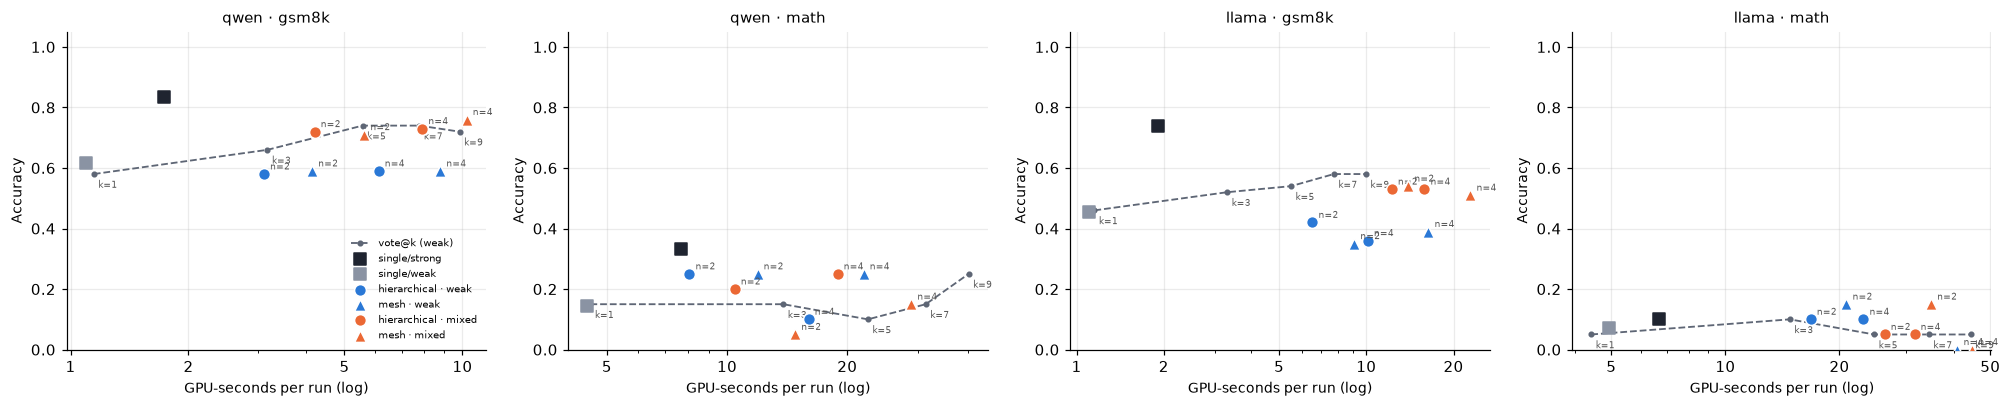

In [25]:
# Figure 1. Accuracy vs. GPU-seconds per run: singles, the vote@k curve, weak and mixed swarms
if PANELS:
    fig, axes = plt.subplots(1, len(PANELS), figsize=(4.6 * len(PANELS), 3.8), squeeze=False)
    for ax, (fam, dom) in zip(axes[0], PANELS):
        s = summary[(summary.family == fam) & (summary.domain == dom)]
        if len(vote_task):
            v = votes[(votes.family == fam) & (votes.domain == dom)].sort_values("k")
            ax.plot(v.gpu_s, v.accuracy, color=COL["vote"], lw=1.2, ls="--", marker=".", label="vote@k (weak)")
            for _, r in v.iterrows():
                ax.annotate(f"k={int(r.k)}", (r.gpu_s, r.accuracy), textcoords="offset points", xytext=(3, -9), fontsize=6, color="#555")
        for cfg in ("single/strong", "single/weak"):
            r = s[s.config == cfg]
            if len(r):
                ax.scatter(r.gpu_s, r.quality, s=70, marker="s", color=COL[cfg], zorder=3, label=cfg)
        for team in TEAMS:
            for a in ARCHITECTURES:
                r = s[(s.team == team) & (s.arch == a)]
                if len(r):
                    ax.scatter(r.gpu_s, r.quality, s=60, marker=MARK[a], color=COL[team], edgecolor="white", zorder=3, label=f"{a} · {team}")
                    for _, x in r.iterrows():
                        ax.annotate(f"n={x.n}", (x.gpu_s, x.quality), textcoords="offset points", xytext=(4, 3), fontsize=6, color="#555")
        ax.set(xscale="log", ylim=(0, 1.05), xlabel="GPU-seconds per run (log)", ylabel="Accuracy", title=f"{fam} · {dom}" + STAMP)
        ax.xaxis.set_major_locator(mticker.LogLocator(base=10, subs=(1, 2, 5)))
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}"))
        ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    axes[0][0].legend(fontsize=6.5, loc="lower right")
    fig.tight_layout(); save(fig, "accuracy_vs_gpu_seconds"); plt.show()

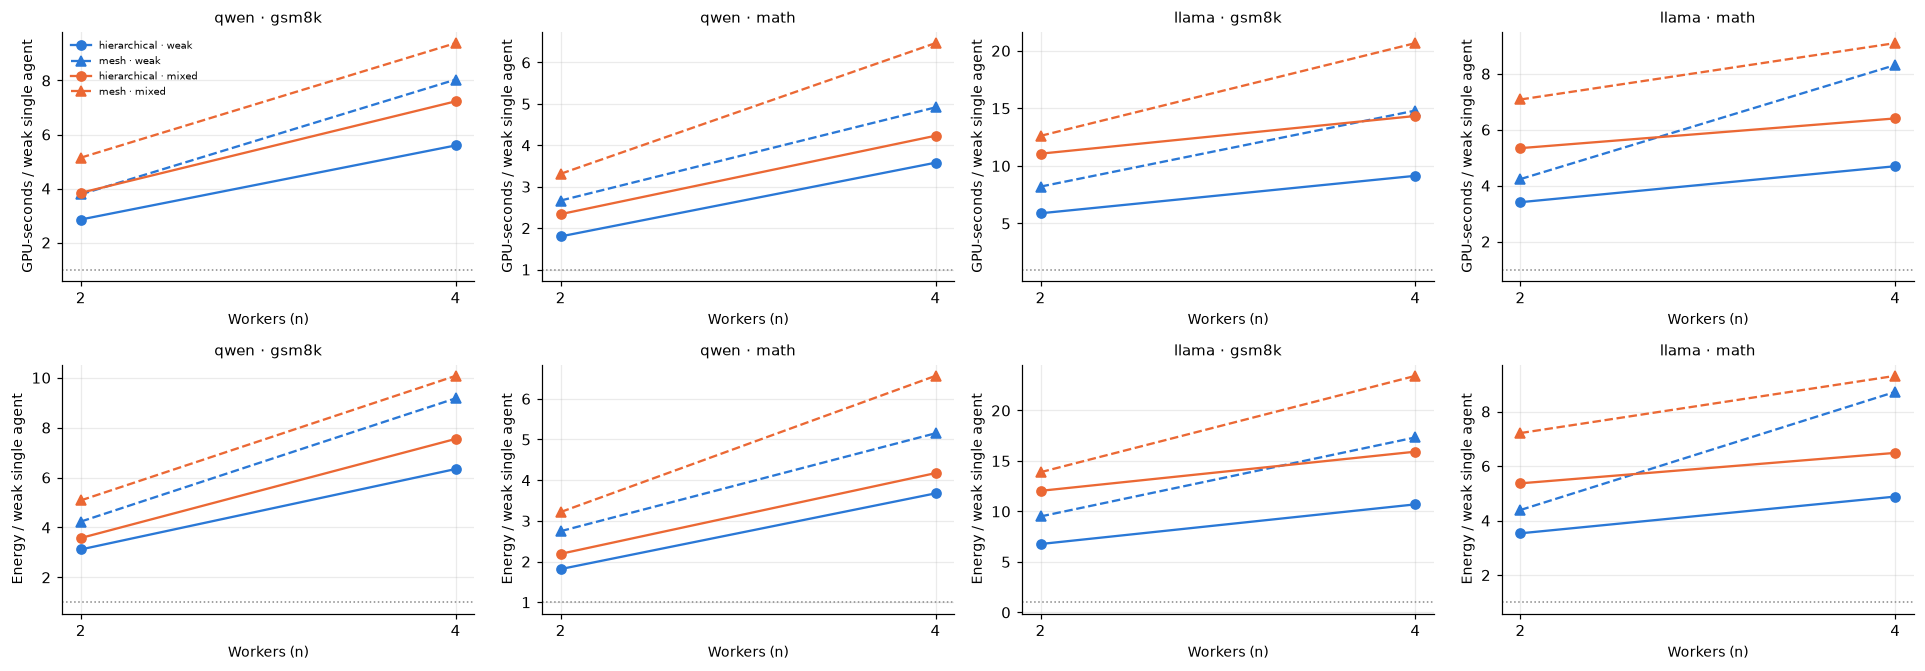

In [26]:
# Figure 2. Cost growth with n: GPU-seconds and energy relative to the weak single agent
if PANELS:
    fig, axes = plt.subplots(2, len(PANELS), figsize=(4.4 * len(PANELS), 6.2), squeeze=False)
    for j, (fam, dom) in enumerate(PANELS):
        s = summary[(summary.family == fam) & (summary.domain == dom)]
        for i, metric in enumerate(("gpu_s_x_weak", "energy_j_x_weak")):
            ax = axes[i][j]
            for team in TEAMS:
                for a in ARCHITECTURES:
                    r = s[(s.team == team) & (s.arch == a)].sort_values("n")
                    if len(r) and r[metric].notna().any():
                        ax.plot(r.n, r[metric], marker=MARK[a], color=COL[team], ls="-" if a == "hierarchical" else "--", label=f"{a} · {team}")
            ax.axhline(1, color="#888", lw=1, ls=":")
            ax.set(xticks=N_WORKERS, xlabel="Workers (n)", ylabel=("GPU-seconds" if i == 0 else "Energy") + " / weak single agent",
                   title=f"{fam} · {dom}" + STAMP)
    axes[0][0].legend(fontsize=6.5)
    fig.tight_layout(); save(fig, "cost_growth"); plt.show()

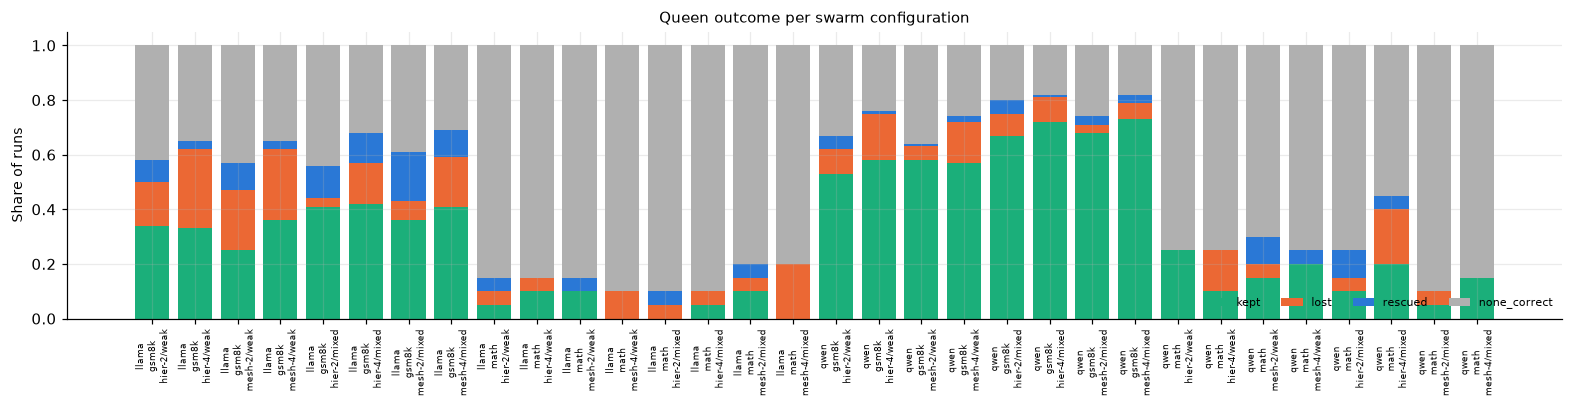

In [27]:
# Figure 3. Coordination outcomes: did the queen keep a worker's correct answer?
if coord is not None and len(coord):
    fig, ax = plt.subplots(figsize=(max(8, 0.45 * len(coord)), 3.8))
    cats, colors = ["kept", "lost", "rescued", "none_correct"], ["#1baf7a", "#eb6834", "#2a78d6", "#b0b0b0"]
    bottom = np.zeros(len(coord))
    for c, col in zip(cats, colors):
        ax.bar(range(len(coord)), coord[c].to_numpy(), bottom=bottom, color=col, width=0.8, label=c)
        bottom += coord[c].to_numpy()
    ax.set_xticks(range(len(coord)), [f"{f}\n{d}\n{c}" for f, d, c in coord.index], fontsize=6, rotation=90)
    ax.set(ylabel="Share of runs", ylim=(0, 1.05), title="Queen outcome per swarm configuration" + STAMP)
    ax.legend(fontsize=7, ncol=4, loc="lower right")
    fig.tight_layout(); save(fig, "coordination"); plt.show()

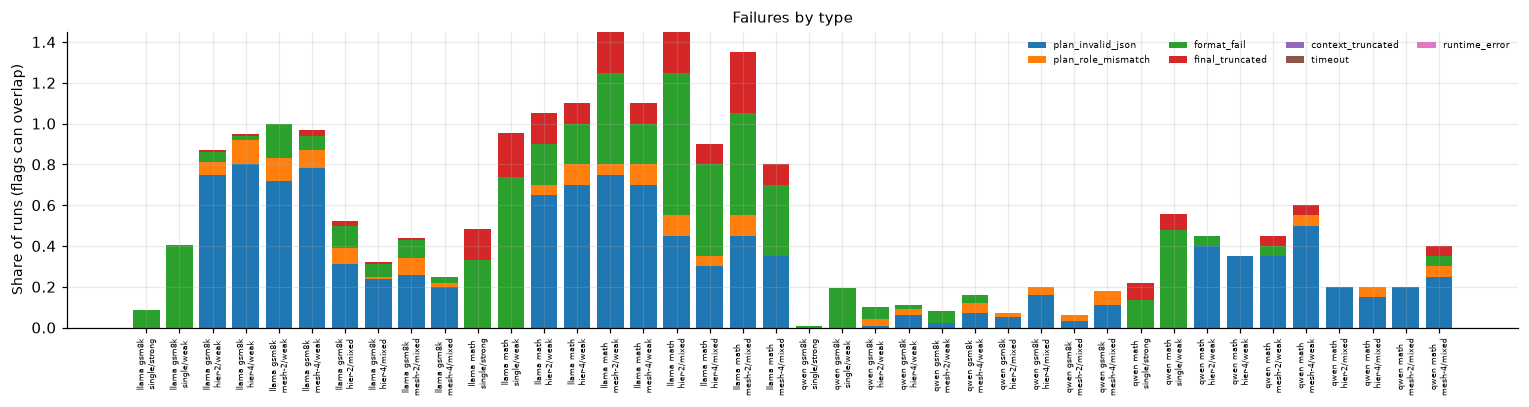

In [28]:
# Figure 4. Failure rates by type
show_flags = ["plan_invalid_json", "plan_role_mismatch", "format_fail", "final_truncated", "context_truncated", "timeout", "runtime_error"]
s = summary[summary.domain.isin([d for d in DOMAINS if DOMAINS[d].kind == "verifiable"])]
if len(s):
    fig, ax = plt.subplots(figsize=(max(8, 0.35 * len(s)), 3.8))
    bottom = np.zeros(len(s))
    for i, f in enumerate(show_flags):
        v = s[f"rate_{f}"].to_numpy()
        ax.bar(range(len(s)), v, bottom=bottom, color=plt.cm.tab10(i), width=0.8, label=f)
        bottom += v
    ax.set_xticks(range(len(s)), [f"{r.family} {r.domain}\n{r.config}" for r in s.itertuples()], fontsize=5.5, rotation=90)
    ax.set(ylabel="Share of runs (flags can overlap)", title="Failures by type" + STAMP)
    ax.legend(fontsize=6, ncol=4)
    fig.tight_layout(); save(fig, "failures"); plt.show()

## 12. Data-derived statements

Generated from the tables above; no hand-written numbers.

In [29]:
print(("⚠ MOCK DATA: statements below only show that the analysis works.\n" if IS_MOCK else "") + "=" * 78)
for (fam, dom), g in summary.groupby(["family", "domain"]):
    best = g.loc[g.quality.idxmax()] if g.quality.notna().any() else None
    if best is not None:
        ok = g[g.quality >= 0.95 * best.quality].sort_values("gpu_s")
        cheap = ok.iloc[0]
        print(f"[{fam} · {dom}] best: {best.config} ({best.quality:.2f}); cheapest within 95% of the best: "
              f"{cheap.config} ({cheap.quality:.2f}, {cheap.gpu_s_x_weak:.1f}× the weak single agent's GPU-seconds).")
if len(contrasts):
    sig = contrasts[contrasts.p_holm < 0.05]
    print(f"Pre-registered contrasts: {len(contrasts)}; significant after Holm: {len(sig)}.")
    for r in sig.itertuples():
        print(f"  {r.hypothesis} [{r.family} · {r.domain}] {r.contrast}: Δ = {r.delta:+.2f} (95% CI {r.ci_lo:+.2f} to {r.ci_hi:+.2f}), p_holm = {r.p_holm:.3f}")
trunc = summary[summary.rate_context_truncated > 0]
print("Context truncation: none." if trunc.empty else
      "Context truncation in: " + ", ".join(f"{r.family}/{r.domain}/{r.config} ({r.rate_context_truncated:.0%})" for r in trunc.itertuples()))

[llama · gsm8k] best: single/strong (0.74); cheapest within 95% of the best: single/strong (0.74, 1.7× the weak single agent's GPU-seconds).
[llama · math] best: mesh-2/weak (0.15); cheapest within 95% of the best: mesh-2/weak (0.15, 4.2× the weak single agent's GPU-seconds).
[llama · travel] best: single/strong (0.86); cheapest within 95% of the best: single/strong (0.86, 1.5× the weak single agent's GPU-seconds).
[qwen · gsm8k] best: single/strong (0.83); cheapest within 95% of the best: single/strong (0.83, 1.6× the weak single agent's GPU-seconds).
[qwen · math] best: single/strong (0.33); cheapest within 95% of the best: single/strong (0.33, 1.7× the weak single agent's GPU-seconds).
[qwen · travel] best: mesh-2/weak (0.57); cheapest within 95% of the best: mesh-2/weak (0.57, 7.5× the weak single agent's GPU-seconds).
Pre-registered contrasts: 80; significant after Holm: 3.
  H4 [llama · gsm8k] hier-4/mixed − single/strong: Δ = -0.21 (95% CI -0.31 to -0.11), p_holm = 0.031
  H4 [l

## 13. Conclusions and limitations

*Written on 2026-10-12 after reading the outputs of sections 8–12. Every number below is copied from those tables. If the results change, this section must be rewritten.*

**Execution.**
- 3,640 evaluation runs (plus 160 calibration runs), with no infrastructure failure and no context truncation.
- The full grid took 10.0 h on one RTX 3050 Laptop GPU (4 GB), with every model 100% in VRAM.

### Hypotheses

| # | Verdict | Evidence |
|---|---|---|
| H1 cost is structural | **Supported** | Swarms cost 1.8–20.7× the weak single agent's GPU-seconds on GSM8K/MATH, and up to 26× its tokens. Mesh-4 is the most expensive shape. Energy follows GPU-seconds, at 55–73 J per GPU-second in every configuration. Both families rank the configurations by cost almost identically (τ = 0.82–0.96). |
| H2 weak swarm vs. weak single | **No improvement** | GSM8K: Δ = −0.03 to −0.04 (Qwen) and −0.04 to −0.11 (Llama). MATH Qwen: +0.11 in 3 of 4 shapes, CIs include 0. Nothing survives Holm. |
| H3 swarm vs. equal-compute voting | **Not supported** | Weak swarms fall below vote@k on GSM8K: −0.08 to −0.15 (Qwen) and −0.10 to −0.19 (Llama). The raw p is < 0.05 in 6 of 8 contrasts, but none survives Holm. Mixed swarms are on par with voting (−0.07 to +0.06). |
| H4 mixed swarm vs. strong single | **The strong single agent wins** | GSM8K: Δ = −0.07 to −0.12 (Qwen) and −0.20 to −0.23 (Llama). The mixed swarms cost 2.4–5.9× (Qwen) and 6.4–12.0× (Llama) the strong agent's GPU-seconds. These are the only contrasts significant after Holm (3 of 80: Llama GSM8K hier-4, mesh-2, mesh-4). |
| H5 the queen matters | **Supported on GSM8K (descriptive)** | Replacing only the queen with the strong model raises accuracy by +0.12 to +0.17 (Qwen) and +0.11 to +0.19 (Llama). The raw p is ≤ 0.06 in 6 of 8 contrasts; none survives Holm. The mechanism differs by family. With Llama, plan failures fall from 81–92% to 22–39% of runs. With Qwen, plans were already valid, and the strong queen keeps a correct worker answer more often (kept 0.67–0.73 vs. 0.53–0.58). No effect on MATH. |
| H6 coordination | Descriptive | On GSM8K the queen discarded a correct worker answer in 3–29% of runs. The mesh review improved the number of correct workers in 20–43% of runs and worsened it in 8–21%. |
| H7 correlated errors | **Supported, with a caveat** | Mean pairwise error correlation φ = 0.24–0.45. Voting helps but saturates: Qwen GSM8K goes 0.62 → 0.74 at k = 5 and falls to 0.72 at k = 9, below the 0.77 predicted under independence. When single accuracy is below 0.5, the binary Condorcet prediction is not an adequate reference: wrong numeric answers scatter, so plurality voting still beats it. |
| H8 agnosticism | Cost: yes. Quality: partly | Same quality ranking on GSM8K (τ = 0.58, p = 0.023), but not on MATH (τ = −0.13) or Cartagena (τ = 0.15). |

### Answer to the research question

With 1–3B local models, adding agents and communication **did not pay off**. In 4 of 6 family × domain cells, the best configuration was the strong single agent, at 1.5–1.7× the weak agent's GPU-seconds. A swarm is nominally best in only two cells, both within noise:
- Llama MATH, a floor regime with 0.15 at best;
- Qwen Cartagena, with 0.57 on 2 answers per configuration, at 7.5× the cost.

When a stronger model is available, it should be used alone. When only the weak model is available, voting over k samples is at least as good as a swarm with the same number of calls. The one lever that clearly helped is a **more capable coordinator**: the swarms' weakness is coordination (MAST FM-1.1 and the lost answers), not the workers.

**Cartagena (open task, LLM rubric, amendment C).**
- Mean score is 0.61 for single agents, 0.48 for mesh and 0.39 for hierarchical swarms.
- Truncated answers score 0.40, against 0.51 for complete ones.
- Almost no answer gives two risks with mitigations (c5: 1 of 40) or a consistent budget (c6: 4 of 40).
- The weak models make frequent factual errors about Cartagena.

### Limitations

- **Models and hardware:** only 1–3B models on a 4 GB laptop GPU, at temperature 0.7, with prompts not tuned per model. Larger models or other prompts may behave differently.
- **Sample sizes:** 50 GSM8K and 20 MATH problems (amendment B). Most contrasts are underpowered, and Holm over 80 contrasts is conservative.
- **Floor regime:** Llama 1B on MATH is at the floor, so that cell carries almost no information.
- **Plan-failure fallback:** when a plan is invalid, every worker gets the full task. The weak Llama swarm therefore mostly measures that fallback: repeated solving plus integration.
- **Cartagena evaluation:**
  - one task, 2 answers per configuration;
  - a single LLM rater instead of two humans (amendment C);
  - many swarm answers cut at the 1,024-token output limit.
- **Energy coverage:** energy is GPU board power only, without CPU or the rest of the system. Model-swap costs are logged separately and are not included in the per-run figures.
- **Equal-compute matching:** voting is matched to swarms by number of calls, not by GPU-seconds. At matched calls the swarm uses as much or more GPU time, so the match does not handicap the swarm.